# CloudShield · Comparative Study · TON_IoT

**23CSE301 Machine Learning · Capstone · Review 2**

This notebook compares the algorithms of the two Review 2 tracks side by side, beyond a single score:

| Part | What is compared | Sections |
|---|---|---|
| Classification | the 10 algorithms (12 configurations: base and tuned Bagging and Gradient Boosting) | 1.1 – 1.11 |
| Clustering | K-Means and Agglomerative (four linkages), plus four extra algorithms for reference | 2.1 – 2.9 |

The data preparation is **copied unchanged** from `03_classification_1.ipynb` and `clustering.ipynb`: same rows, same machine-grouped train/test split, same features, same model settings. Every model is refitted here so its training time, predictions and scores can be compared directly.

Tables are saved to `results/comparative/` and figures to `results/figures/comparative/`.

In [1]:
import os, time, warnings
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("future.infer_string", False)
pd.set_option("display.width", 200)
ROOT = ".." if os.path.isdir(os.path.join("..", "data")) else "."
OUT = os.path.join(ROOT, "results", "comparative")
FIG = os.path.join(ROOT, "results", "figures", "comparative")
os.makedirs(OUT, exist_ok=True)
os.makedirs(FIG, exist_ok=True)
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["figure.dpi"] = 110


def save(fig, name):
    fig.savefig(os.path.join(FIG, name), dpi=150, bbox_inches="tight")
    print("saved", os.path.join("results", "figures", "comparative", name))

# Part 1 · Classification: the 10 algorithms

## 1.0 Data preparation (identical to `03_classification_1.ipynb`)
45,000-flow stratified sample, machine-grouped split (no `src_ip` on both sides, all 10 traffic types on both sides), engineered features, then median-impute + scale for numbers and one-hot for categories, fitted on the training rows only.

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import precision_score, recall_score  # Part-A + final per-class report
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split,StratifiedGroupKFold
import os


# text columns as object dtype on every pandas version, so the categorical
# columns are detected the same way everywhere
pd.set_option('future.infer_string', False)
# project root, whether the notebook runs from notebooks/ or from the root
ROOT = '..' if os.path.isdir(os.path.join('..', 'data')) else '.'

In [3]:
folder = 'data/raw/TON_IoT'
path = os.path.join(ROOT, folder, 'train_test_network.csv')
df = pd.read_csv(path)
print('raw:', df.shape)

raw: (211043, 44)


In [4]:
df = df.drop_duplicates(ignore_index=True)

# ---- Stratified down-sample to 45k rows ----------------------------------
# The deduplicated table has 190k rows, which makes GBC / SVC / MLP and the
# cross-validation at the end take a long time. A stratified sample keeps the
# per-class proportions of the original data, so all 10 attack types keep the
# same relative support they had in the full set.
from sklearn.model_selection import train_test_split

SAMPLE_N = 45000
df, _ = train_test_split(df, train_size=SAMPLE_N, stratify=df["type"], random_state=42)
df = df.reset_index(drop=True)

print("Sampled rows:", len(df))
print(df["type"].value_counts().to_string())

Sampled rows: 45000
type
normal        9932
scanning      4725
ddos          4723
injection     4717
password      4692
dos           4487
backdoor      4421
xss           3576
ransomware    3481
mitm           246


In [5]:
NEED = ["proto","service","conn_state","duration","src_bytes","dst_bytes","missed_bytes",
        "src_pkts","dst_pkts","src_ip_bytes","dst_ip_bytes","dns_qtype","dns_rcode",
        "dns_AA","dns_RD","dns_RA","dns_rejected","dns_qclass","dst_port","src_ip","dst_ip","label","type"]
LOG  = ["duration","src_bytes","dst_bytes","src_pkts","dst_pkts","src_ip_bytes","dst_ip_bytes"]
CAT  = ["proto","service","conn_state"]
DNS_S   = ["dns_AA","dns_RD","dns_RA","dns_rejected"]
DROP_AFT = DNS_S + ["dns_qclass", "missed_bytes", "src_ip", "dst_ip"]

cols = [
    'http_user_agent',
    'http_orig_mime_types',
    'http_resp_mime_types',
    'weird_name',
    'weird_addl',
    'weird_notice'
]
cols1 = [
    'http_trans_depth',
    'http_method',
    'http_uri',
    'http_version'
]


ssl_keep = [
    "ssl_version",
    "ssl_cipher",
    "ssl_resumed",
    "ssl_established"
]

ssl_drop = ["ssl_subject", "ssl_issuer"]

df[ssl_keep] = df[ssl_keep].replace("-", "Unknown")
df = df.drop(columns=ssl_drop)

df=df.drop(cols+cols1, axis=1)


df = df.sample(frac=1,random_state=42,ignore_index=True)

# StratifiedGroupKFold keeps every src_ip machine entirely on one side of the
# split, so no machine shows up in train AND test. With only ~47 machines and a
# few attack types living on 2 of them, one arbitrary fold can leave a whole
# class out of the test set (the old 5-fold pick dropped 4 of the 10 types).
# So: 3 folds, then step through seeds and take the first fold whose test AND
# training sides both contain all 10 attack types - same grouping rule, just a
# reproducible pick that makes every metric below complete.
# Grouped split, hand-built from the per-machine histogram (see probe in plan):
# backdoor lives on 3 machines (.193/.33/.37), xss and password on 2 each, so
# a blind seed search almost never satisfies every class at once. Assignment:
# .193+.37 -> train (backdoor train 4884), .33 -> test (backdoor test 28);
# .32 -> train (xss 3825), .36 -> test (xss 148); .30 -> train / .31 -> test
# (password/ddos/injection/scanning split); .34 -> train / .31 -> test (mitm);
# .195+.180 -> test so the test side gets ~2k normal rows (.31/.32/.33/.36/.37
# carry almost no normal traffic). Every src_ip stays wholly on one side.
TEST_MACHINES = {'192.168.1.31', '192.168.1.33', '192.168.1.36', '192.168.1.39',
                 '192.168.1.180', '192.168.1.195'}
_te_mask = df['src_ip'].isin(TEST_MACHINES).to_numpy()
test = np.where(_te_mask)[0]
train = np.where(~_te_mask)[0]
assert len(set(df['src_ip'].iloc[train]) & set(df['src_ip'].iloc[test])) == 0
assert set(df["type"].iloc[train]) == set(df["type"]) == set(df["type"].iloc[test]), \
    "every class must appear on both sides"
print(f"Grouped split: train {len(train)} rows / test {len(test)} rows, "
      f"all 10 classes on both sides, 0 shared machines")
X_train = df.iloc[train]
X_test = df.iloc[test]

# Support tables: who trains on what, who gets tested on what
sup = pd.DataFrame({
    'train': df["type"].iloc[train].value_counts(),
    'test': df["type"].iloc[test].value_counts(),
})
sup['train_machines'] = df.iloc[train].groupby('type')['src_ip'].nunique()
sup['test_machines'] = df.iloc[test].groupby('type')['src_ip'].nunique()
print(sup.to_string())

X_train = df.iloc[train]
X_test = df.iloc[test]

fit = {
  "dur_hi":X_train["duration"].quantile(0.999),
  "ports": set(X_train["dst_port"].value_counts().head(10)),
  "sports": set(X_train["src_port"].value_counts().head(50)),
}

def build(d,fit):
  df = d.copy()
  df['dns_present'] = d[DNS_S].ne('-').any(axis=1).astype("int8")
  df['dns_query_parsed'] = d['service'].eq("dns").astype("int8")
  df['has_missed'] = df['missed_bytes'].gt(0).astype("int8")
  # dst_ip has 753 distinct values (mostly host ids like 192.168.1.x), so it
  # would leak machine identity through the one-hot encoder; keep only whether
  # the destination is internal.
  df['dst_internal'] = d['dst_ip'].astype(str).str.startswith('192.168.1.').astype("int8")
  df['duration'] = df['duration'].clip(upper=fit["dur_hi"]) # ,d['dst_port]
  df[LOG] = np.log1p(df[LOG].to_numpy()) # we are applying log transformations
  df["dst_port"] = np.where(df['dst_port'].isin(fit["ports"]),df['dst_port'],-1).astype("int16")
  df["src_port"] = np.where(df['src_port'].isin(fit["sports"]),df['src_port'],-1).astype("int16")
  # proto/service/conn_state stay strings here: cell 9 one-hots them, which
  # treats each value as its own flag instead of an ordered number.
  return df.drop(columns=DROP_AFT+["type","label"])


Y_train,Y_test = df["type"].iloc[train].values,df["type"].iloc[test].values

X_train,X_test = build(X_train,fit), build(df.iloc[test],fit)

Grouped split: train 33912 rows / test 11088 rows, all 10 classes on both sides, 0 shared machines
            train  test  train_machines  test_machines
type                                                  
backdoor     4395    26               2              1
ddos         3916   807               3              1
dos          4179   308               1              2
injection    1849  2868               2              1
mitm          121   125               1              2
normal       8068  1864              35              2
password     2281  2411               1              1
ransomware   1778  1703               3              1
scanning     3882   843               3              1
xss          3443   133               1              1


In [6]:
from sklearn.ensemble import (
  RandomForestClassifier,
  AdaBoostClassifier,
  GradientBoostingClassifier,
  BaggingClassifier,
)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

numerical_cols = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=20
    ))
])

processor = ColumnTransformer([
    ("num", numeric_pipe, numerical_cols),
    ("cat", categorical_pipe, categorical_cols),
])

X_train1 = processor.fit_transform(X_train)
X_test1 = processor.transform(X_test)

# Names for BOTH numerical and categorical features
feature_names = processor.get_feature_names_out()

X_train_df = pd.DataFrame(
    X_train1.toarray() if hasattr(X_train1, "toarray") else X_train1,
    columns=feature_names,
    index=X_train.index
)

X_test_df = pd.DataFrame(
    X_test1.toarray() if hasattr(X_test1, "toarray") else X_test1,
    columns=feature_names,
    index=X_test.index
)

print("Train shape:", X_train_df.shape)
print("Test shape:", X_test_df.shape)

Train shape: (33912, 83)
Test shape: (11088, 83)


In [7]:
# numpy views and the 12k SVC subsample, exactly as in 03_classification_1.ipynb (Part A setup)
X_tr = np.asarray(X_train_df, dtype=np.float64)
X_te = np.asarray(X_test_df, dtype=np.float64)
y_tr = np.asarray(Y_train, dtype=object)
y_te = np.asarray(Y_test, dtype=object)
SUBSAMPLE_N = 12000
rng = np.random.RandomState(42)
_parts = []
for cls in sorted(set(y_tr.tolist())):
    idx = np.where(y_tr == cls)[0]
    n = max(1, int(round(len(idx) * SUBSAMPLE_N / len(X_tr))))
    _parts.append(rng.choice(idx, size=min(n, len(idx)), replace=False))
sub_idx = np.sort(np.concatenate(_parts))
X_sub, y_sub = X_tr[sub_idx], y_tr[sub_idx]
LABELS = sorted(set(y_te.tolist()))
groups_tr = df['src_ip'].iloc[train].values
print('train', X_tr.shape, '| test', X_te.shape, '| SVC subsample', X_sub.shape, '| classes', len(LABELS))

train (33912, 83) | test (11088, 83) | SVC subsample (12000, 83) | classes 10


## 1.1 The 12 configurations

Settings copied from `03_classification_1.ipynb`. The two tuned rows use the configurations its tuning cell selected with grouped 3-fold CV on the training set:

* Bagging (tuned): `n_estimators=200, max_features=0.3, estimator__max_depth=None`
* Gradient Boosting (tuned): `n_estimators=100, learning_rate=0.05, max_depth=4, subsample=0.8`

Models without a `class_weight` option (AdaBoost, Gradient Boosting) get balanced sample weights, as in the source notebook. Part A models train on the numpy matrix (SVC on the 12k subsample); Part B models on the DataFrame.

In [8]:
from sklearn.base import clone
from sklearn.utils.class_weight import compute_sample_weight

_bag = BaggingClassifier(estimator=DecisionTreeClassifier(class_weight='balanced', random_state=42), n_estimators=100,
                         max_samples=1.0, max_features=0.3, bootstrap=True, random_state=42, n_jobs=-1)
_gbc = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)

# name: (estimator, part, family, training data, balanced sample weights?)
CONFIGS = {
    'Logistic Regression': (LogisticRegression(C=1.0, max_iter=3000, class_weight='balanced', n_jobs=-1), 'A', 'Linear', 'np', False),
    'K-Nearest Neighbors': (KNeighborsClassifier(n_neighbors=5, weights='distance', n_jobs=-1), 'A', 'Distance-based', 'np', False),
    'Gaussian NB': (GaussianNB(), 'A', 'Probabilistic', 'np', False),
    'Decision Tree': (DecisionTreeClassifier(max_depth=None, class_weight='balanced', random_state=42), 'A', 'Single tree', 'np', False),
    'SVC (RBF)': (SVC(kernel='rbf', C=1.0, class_weight='balanced'), 'A', 'Kernel', 'sub', False),
    'Random Forest': (RandomForestClassifier(n_estimators=200, class_weight='balanced_subsample', random_state=42, n_jobs=-1),
                      'B', 'Bagging ensemble', 'df', False),
    'AdaBoost': (AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=3, random_state=42), n_estimators=100,
                                    learning_rate=1.0, random_state=42), 'B', 'Boosting ensemble', 'df', True),
    'Gradient Boosting': (_gbc, 'B', 'Boosting ensemble', 'df', True),
    'Bagging': (_bag, 'B', 'Bagging ensemble', 'df', False),
    'Neural Network': (MLPClassifier(hidden_layer_sizes=(100, 50), activation='relu', solver='adam', alpha=0.0001,
                                     learning_rate_init=0.001, max_iter=300, random_state=42), 'B', 'Neural network', 'df', False),
    'Bagging (tuned)': (clone(_bag).set_params(n_estimators=200, max_features=0.3, estimator__max_depth=None),
                        'B', 'Bagging ensemble', 'df', False),
    'Gradient Boosting (tuned)': (clone(_gbc).set_params(n_estimators=100, learning_rate=0.05, max_depth=4, subsample=0.8),
                                  'B', 'Boosting ensemble', 'df', True),
}
pd.DataFrame([(n, p, f, d) for n, (_, p, f, d, _) in CONFIGS.items()], columns=['Model', 'Part', 'Family', 'Trained on'])

,Model,Part,Family,Trained on
0,Logistic Regression,A,Linear,np
1,K-Nearest Neighbors,A,Distance-based,np
2,Gaussian NB,A,Probabilistic,np
3,Decision Tree,A,Single tree,np
4,SVC (RBF),A,Kernel,sub
5,Random Forest,B,Bagging ensemble,df
6,AdaBoost,B,Boosting ensemble,df
7,Gradient Boosting,B,Boosting ensemble,df
8,Bagging,B,Bagging ensemble,df
9,Neural Network,B,Neural network,df


## 1.2 Fit every configuration (timed)
Training time is the wall-clock `fit` time on this machine; prediction time is for the whole test set. Both are only comparable with each other, not with other machines.

In [9]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, roc_curve, auc)
from sklearn.preprocessing import label_binarize

RUN = {}
for name, (est, part, family, data, sw) in CONFIGS.items():
    Xf, yf = {'np': (X_tr, y_tr), 'sub': (X_sub, y_sub), 'df': (X_train_df, y_tr)}[data]
    Xp = X_test_df if data == 'df' else X_te
    kw = {'sample_weight': compute_sample_weight(class_weight='balanced', y=yf)} if sw else {}
    t0 = time.perf_counter(); est.fit(Xf, yf, **kw); fit_s = time.perf_counter() - t0
    t0 = time.perf_counter(); pred = np.asarray(est.predict(Xp), dtype=object); pred_s = time.perf_counter() - t0
    raw = est.predict_proba(Xp) if hasattr(est, 'predict_proba') else est.decision_function(Xp)
    S = raw[:, [list(est.classes_).index(c) for c in LABELS]]          # one score column per class, LABELS order
    RUN[name] = {'model': est, 'pred': pred, 'scores': S, 'fit_s': fit_s, 'pred_s': pred_s,
                 'part': part, 'family': family, 'proba': hasattr(est, 'predict_proba')}
    print(f'{name:27s} fit {fit_s:7.1f}s   predict {pred_s:6.2f}s   F1w {f1_score(y_te, pred, average="weighted"):.4f}')

Logistic Regression         fit   221.6s   predict   0.06s   F1w 0.7751


K-Nearest Neighbors         fit     0.2s   predict   8.16s   F1w 0.8831


Gaussian NB                 fit     0.3s   predict   0.26s   F1w 0.3243


Decision Tree               fit     0.7s   predict   0.01s   F1w 0.8854


SVC (RBF)                   fit     8.7s   predict  31.98s   F1w 0.8024


...

Gradient Boosting           fit   332.3s   predict   1.52s   F1w 0.8871


Bagging                     fit    62.0s   predict   1.53s   F1w 0.9134


Neural Network              fit   462.6s   predict   0.22s   F1w 0.8795


Bagging (tuned)             fit    26.0s   predict   0.84s   F1w 0.9249


Gradient Boosting (tuned)   fit   176.0s   predict   0.85s   F1w 0.8850


## 1.3 Consolidated comparison table
All 10 algorithms on the same held-out machines, ranked by weighted F1. ROC-AUC is one-vs-rest, averaged over the 10 classes (probabilities, or the SVC decision function).

In [10]:
def metrics(y, p, S):
    return {'Accuracy': accuracy_score(y, p),
            'Precision (w)': precision_score(y, p, average='weighted', zero_division=0),
            'Recall (w)': recall_score(y, p, average='weighted', zero_division=0),
            'F1 (weighted)': f1_score(y, p, average='weighted', zero_division=0),
            'F1 (macro)': f1_score(y, p, average='macro', zero_division=0),
            'ROC-AUC (OvR)': float(np.mean([roc_auc_score(y == c, S[:, i]) for i, c in enumerate(LABELS)]))}

METRICS = ['Accuracy', 'Precision (w)', 'Recall (w)', 'F1 (weighted)', 'F1 (macro)', 'ROC-AUC (OvR)']
table = pd.DataFrame([{'Model': n, 'Part': r['part'], 'Family': r['family'], **metrics(y_te, r['pred'], r['scores']),
                       'Train time (s)': r['fit_s'], 'Predict time (s)': r['pred_s']} for n, r in RUN.items()])
table = table.sort_values('F1 (weighted)', ascending=False).reset_index(drop=True)
table.insert(0, 'Rank', range(1, len(table) + 1))
table.to_csv(os.path.join(OUT, 'classification_comparison.csv'), index=False)
WINNER = table.loc[0, 'Model']
print('best by weighted F1:', WINNER)
table.style.format({m: '{:.4f}' for m in METRICS} | {'Train time (s)': '{:.1f}', 'Predict time (s)': '{:.2f}'}) \
     .background_gradient(subset=METRICS, cmap='Greens').hide(axis='index')

best by weighted F1: Bagging (tuned)


Rank,Model,Part,Family,Accuracy,Precision (w),Recall (w),F1 (weighted),F1 (macro),ROC-AUC (OvR),Train time (s),Predict time (s)
1,Bagging (tuned),B,Bagging ensemble,0.9217,0.9386,0.9217,0.9249,0.8351,0.9894,26.0,0.84
2,Bagging,B,Bagging ensemble,0.9103,0.9337,0.9103,0.9134,0.8463,0.9869,62.0,1.53
3,Gradient Boosting,B,Boosting ensemble,0.8863,0.9257,0.8863,0.8871,0.8344,0.9912,332.3,1.52
4,Decision Tree,A,Single tree,0.8816,0.9230,0.8816,0.8854,0.7799,0.9166,0.7,0.01
5,Gradient Boosting (tuned),B,Boosting ensemble,0.8842,0.9232,0.8842,0.8850,0.8270,0.9923,176.0,0.85
6,Random Forest,B,Bagging ensemble,0.8844,0.9209,0.8844,0.8833,0.8025,0.9883,5.6,0.51
7,K-Nearest Neighbors,A,Distance-based,0.8821,0.9231,0.8821,0.8831,0.8064,0.9522,0.2,8.16
8,Neural Network,B,Neural network,0.8776,0.9181,0.8776,0.8795,0.7621,0.9607,462.6,0.22
9,AdaBoost,B,Boosting ensemble,0.8508,0.8875,0.8508,0.8540,0.7492,0.9735,63.8,1.52
10,SVC (RBF),A,Kernel,0.7771,0.8613,0.7771,0.8024,0.6791,0.9374,8.7,31.98


In [11]:
# cross-check: the same scores as the leaderboard of 03_classification_1.ipynb, when that file is present
ref_path = os.path.join(ROOT, 'results', 'classification_10model_ton_iot.csv')
if os.path.exists(ref_path):
    ref = pd.read_csv(ref_path).set_index('Model')
    chk = table.set_index('Model')[['F1 (weighted)']].join(ref[['F1w test']], how='inner')
    chk['difference'] = (chk['F1 (weighted)'] - chk['F1w test']).abs()
    print(chk.round(4).to_string())
else:
    print('results/classification_10model_ton_iot.csv not found: run 03_classification_1.ipynb to cross-check')

                     F1 (weighted)  F1w test  difference
Model                                                   
Bagging                     0.9134    0.9134         0.0
Gradient Boosting           0.8871    0.8871         0.0
Decision Tree               0.8854    0.8854         0.0
Random Forest               0.8833    0.8833         0.0
K-Nearest Neighbors         0.8831    0.8831         0.0
Neural Network              0.8795    0.8795         0.0
AdaBoost                    0.8540    0.8540         0.0
SVC (RBF)                   0.8024    0.8024         0.0
Logistic Regression         0.7751    0.7751         0.0
Gaussian NB                 0.3243    0.3243         0.0


> **Observation (write in your own words):** Which algorithm is best on weighted F1, and is it also best on macro F1 and ROC-AUC? Why can the two F1 averages disagree on this data?
>
> _…_

## 1.4 Does the winner depend on the metric? Rank heatmap
Each cell is the rank of a model on one metric (1 = best). Rows are ordered by mean rank. A model whose ranks are all similar is a consistent choice; scattered ranks mean the "best model" depends on what you measure.

saved results\figures\comparative\cls_01_rank_heatmap.png


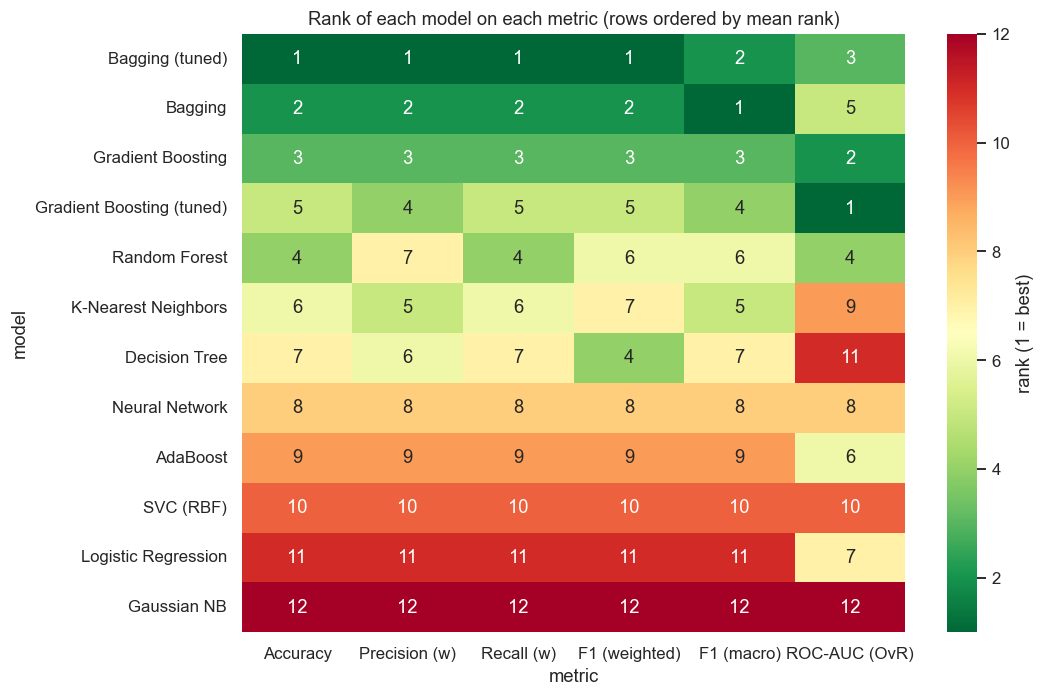

,Accuracy,Precision (w),Recall (w),F1 (weighted),F1 (macro),ROC-AUC (OvR),Mean rank
Model,,,,,,,
Bagging (tuned),1,1,1,1,2,3,1.50
Bagging,2,2,2,2,1,5,2.33
Gradient Boosting,3,3,3,3,3,2,2.83
Gradient Boosting (tuned),5,4,5,5,4,1,4.00
Random Forest,4,7,4,6,6,4,5.17
K-Nearest Neighbors,6,5,6,7,5,9,6.33
Decision Tree,7,6,7,4,7,11,7.00
Neural Network,8,8,8,8,8,8,8.00
AdaBoost,9,9,9,9,9,6,8.50


In [12]:
ranks = table.set_index('Model')[METRICS].rank(ascending=False, method='min').astype(int)
ranks['Mean rank'] = ranks.mean(axis=1)
ranks = ranks.sort_values('Mean rank')
ranks.to_csv(os.path.join(OUT, 'classification_ranks.csv'))
fig, ax = plt.subplots(figsize=(10, 6.5))
sns.heatmap(ranks[METRICS], annot=True, fmt='d', cmap='RdYlGn_r', cbar_kws={'label': 'rank (1 = best)'}, ax=ax)
ax.set_title('Rank of each model on each metric (rows ordered by mean rank)')
ax.set_xlabel('metric'); ax.set_ylabel('model')
plt.tight_layout(); save(fig, 'cls_01_rank_heatmap.png'); plt.show()
ranks.round(2)

> **Observation (write in your own words):** Which models keep a similar rank on every metric, and which jump around? What does that say about choosing a model by one number?
>
> _…_

## 1.5 All metrics side by side
### 1.5.1 Grouped bar chart

saved results\figures\comparative\cls_02_metrics_bars.png


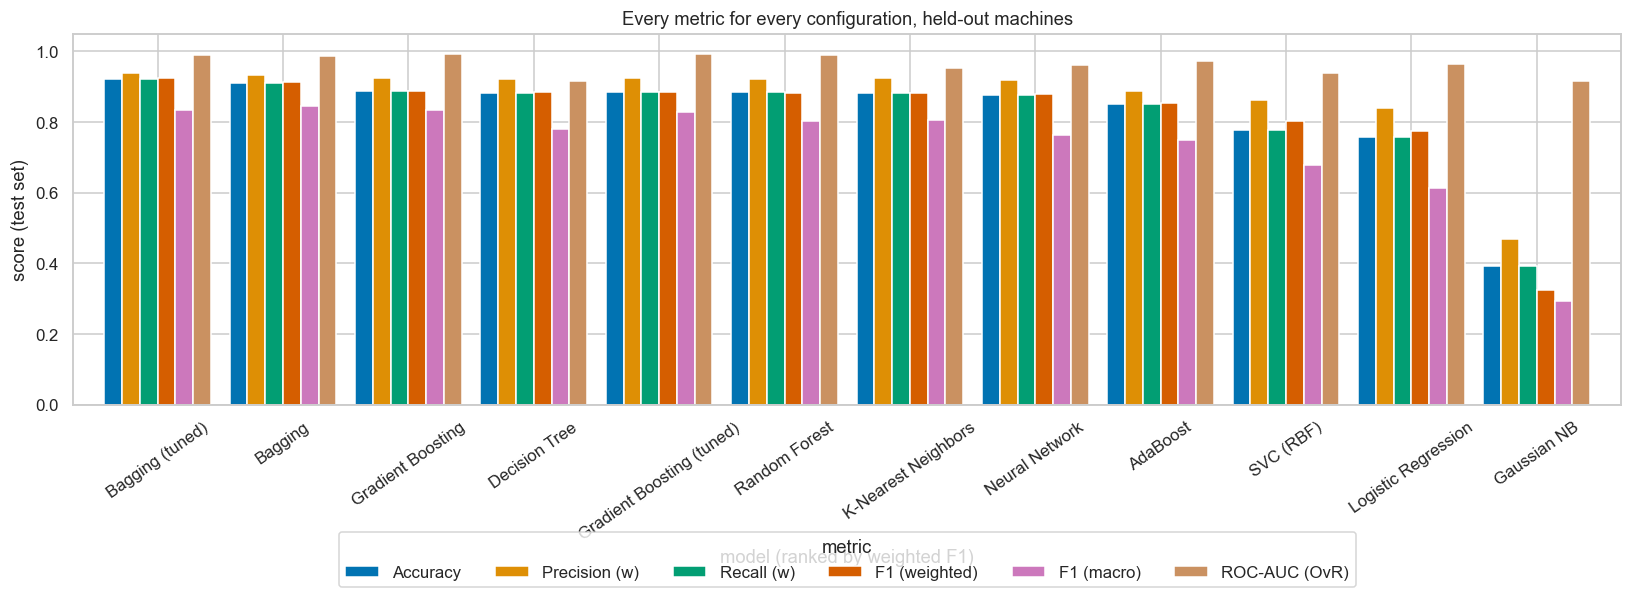

In [13]:
fig, ax = plt.subplots(figsize=(15, 6))
table.set_index('Model')[METRICS].plot(kind='bar', ax=ax, width=0.85, rot=35)
ax.set_ylim(0, 1.05); ax.set_ylabel('score (test set)'); ax.set_xlabel('model (ranked by weighted F1)')
ax.set_title('Every metric for every configuration, held-out machines')
ax.legend(title='metric', ncol=6, loc='upper center', bbox_to_anchor=(0.5, -0.32))
plt.tight_layout(); save(fig, 'cls_02_metrics_bars.png'); plt.show()

### 1.5.2 Radar chart: top five and the linear baseline

saved results\figures\comparative\cls_03_radar.png


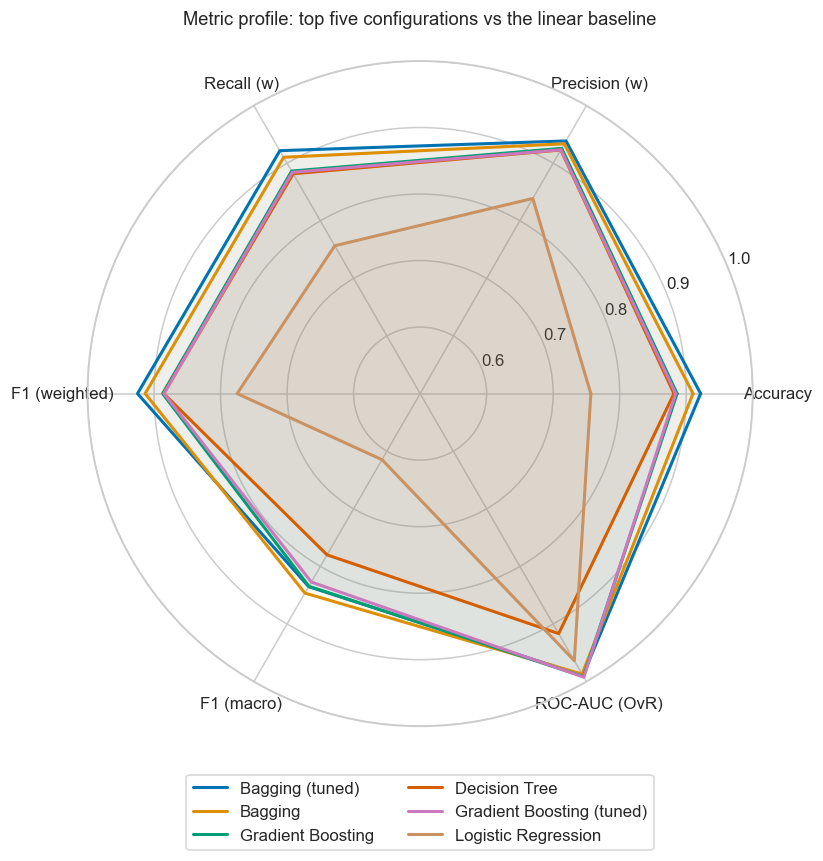

In [14]:
pick = table['Model'].head(5).tolist() + (['Logistic Regression'] if 'Logistic Regression' not in table['Model'].head(5).tolist() else [])
ang = np.linspace(0, 2 * np.pi, len(METRICS), endpoint=False).tolist()
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={'polar': True})
for m in pick:
    v = table.set_index('Model').loc[m, METRICS].astype(float).tolist()
    ax.plot(ang + ang[:1], v + v[:1], lw=2, label=m)
    ax.fill(ang + ang[:1], v + v[:1], alpha=0.06)
ax.set_xticks(ang); ax.set_xticklabels(METRICS); ax.set_ylim(0.5, 1.0)
ax.set_title('Metric profile: top five configurations vs the linear baseline', pad=24)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.06), ncol=2)
plt.tight_layout(); save(fig, 'cls_03_radar.png'); plt.show()

## 1.6 Which algorithm fails on which attack? Per-class F1
Rows are models, columns are traffic types, cells are F1 on the test machines. Test support is printed under each class name.

saved results\figures\comparative\cls_04_per_class_f1.png


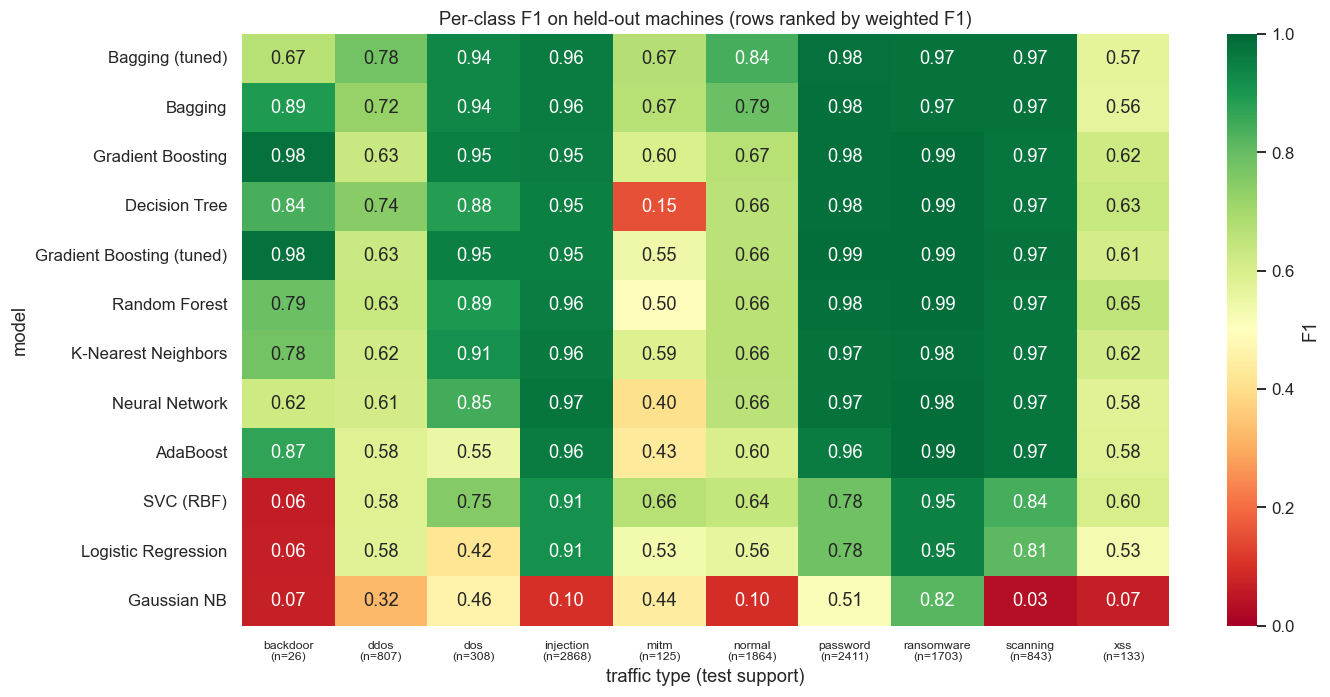

In [15]:
from sklearn.metrics import precision_recall_fscore_support
pc_f1, pc_rec = {}, {}
for n in table['Model']:
    p, r, f, s = precision_recall_fscore_support(y_te, RUN[n]['pred'], labels=LABELS, zero_division=0)
    pc_f1[n], pc_rec[n] = f, r
support = pd.Series(y_te).value_counts().reindex(LABELS)
per_class = pd.DataFrame(pc_f1, index=LABELS).T
per_class_recall = pd.DataFrame(pc_rec, index=LABELS).T
per_class.to_csv(os.path.join(OUT, 'classification_per_class_f1.csv'))
per_class_recall.to_csv(os.path.join(OUT, 'classification_per_class_recall.csv'))
fig, ax = plt.subplots(figsize=(13, 6.5))
sns.heatmap(per_class, annot=True, fmt='.2f', cmap='RdYlGn', vmin=0, vmax=1, cbar_kws={'label': 'F1'}, ax=ax)
ax.set_xticklabels([f'{c}\n(n={support[c]})' for c in LABELS], rotation=0, fontsize=8)
ax.set_title('Per-class F1 on held-out machines (rows ranked by weighted F1)')
ax.set_xlabel('traffic type (test support)'); ax.set_ylabel('model')
plt.tight_layout(); save(fig, 'cls_04_per_class_f1.png'); plt.show()

In [16]:
# hardest and easiest classes across all models, and the best model for each class
summary = pd.DataFrame({'test support': support, 'mean F1 over models': per_class.mean(),
                        'best model': per_class.idxmax(), 'best F1': per_class.max(),
                        'worst model': per_class.idxmin(), 'worst F1': per_class.min()}).sort_values('mean F1 over models')
summary.round(3)

,test support,mean F1 over models,best model,best F1,worst model,worst F1
mitm,125,0.516,Bagging (tuned),0.672,Decision Tree,0.155
xss,133,0.552,Random Forest,0.652,Gaussian NB,0.066
ddos,807,0.620,Bagging (tuned),0.780,Gaussian NB,0.323
normal,1864,0.625,Bagging (tuned),0.841,Gaussian NB,0.096
backdoor,26,0.634,Gradient Boosting,0.980,SVC (RBF),0.059
dos,308,0.791,Gradient Boosting (tuned),0.951,Logistic Regression,0.419
scanning,843,0.870,Bagging,0.975,Gaussian NB,0.033
injection,2868,0.879,Neural Network,0.970,Gaussian NB,0.101
password,2411,0.907,Gradient Boosting (tuned),0.985,Gaussian NB,0.513
ransomware,1703,0.964,Gradient Boosting,0.987,Gaussian NB,0.818


> **Observation (write in your own words):** Which traffic types are hard for every algorithm, and which are hard only for some? Does the test support explain it?
>
> _…_

### 1.6.1 Confusion matrices for all configurations (row-normalised)

saved results\figures\comparative\cls_05_confusion_all.png


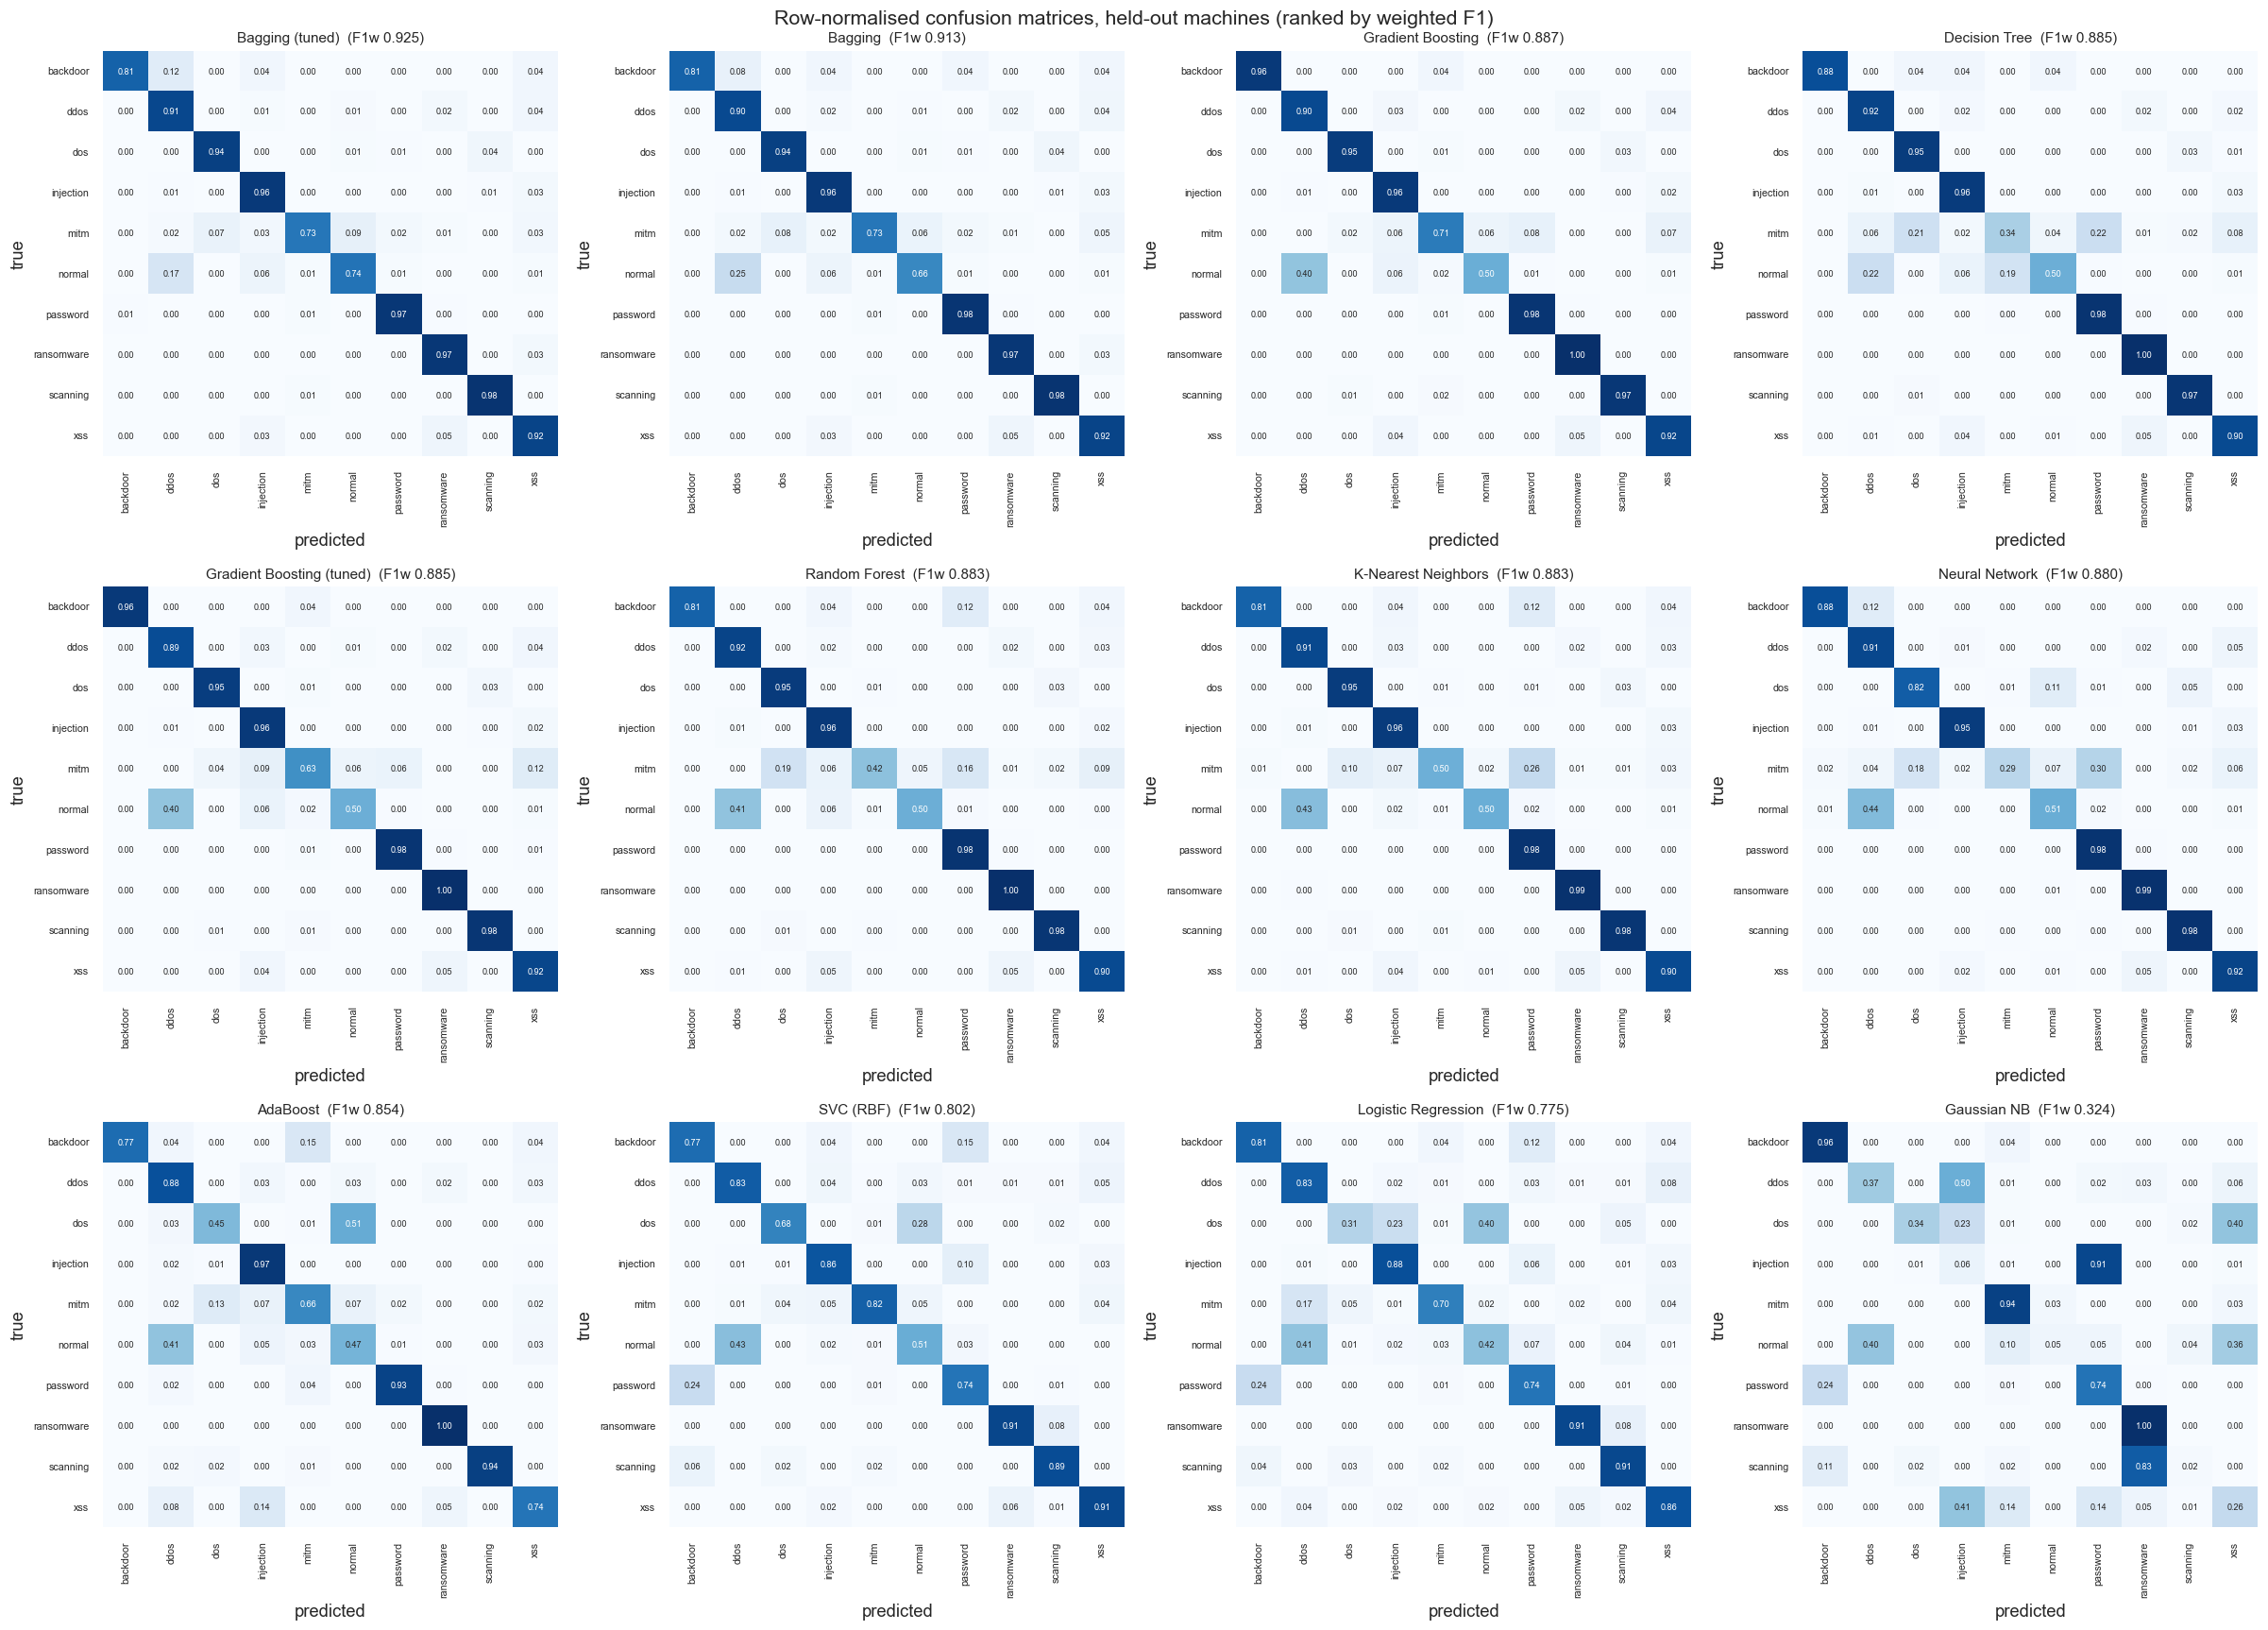

In [17]:
fig, axes = plt.subplots(3, 4, figsize=(22, 16))
for ax, n in zip(axes.ravel(), table['Model']):
    cm = confusion_matrix(y_te, RUN[n]['pred'], labels=LABELS)
    cmn = cm / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cmn, cmap='Blues', vmin=0, vmax=1, cbar=False, ax=ax, xticklabels=LABELS, yticklabels=LABELS,
                annot=True, fmt='.2f', annot_kws={'size': 6})
    ax.set_title(f"{n}  (F1w {table.set_index('Model').loc[n, 'F1 (weighted)']:.3f})", fontsize=10)
    ax.set_xlabel('predicted'); ax.set_ylabel('true'); ax.tick_params(labelsize=7)
fig.suptitle('Row-normalised confusion matrices, held-out machines (ranked by weighted F1)', fontsize=14)
plt.tight_layout(); save(fig, 'cls_05_confusion_all.png'); plt.show()

### 1.6.2 ROC curves of all configurations (micro-average, one-vs-rest)

saved results\figures\comparative\cls_06_roc_all.png


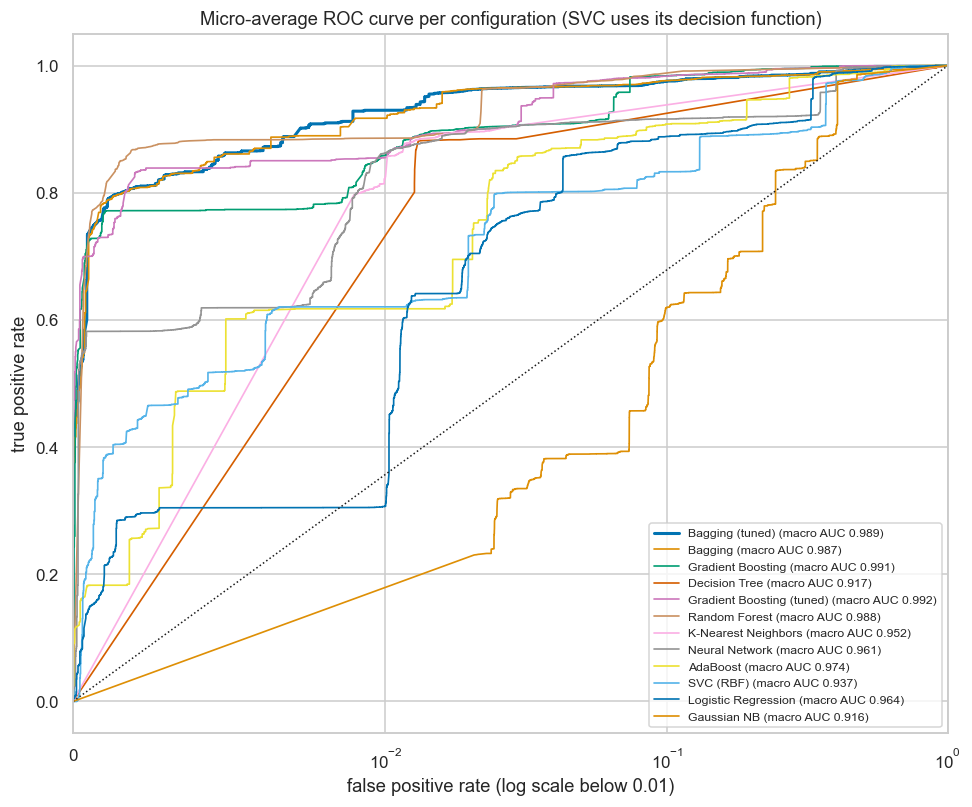

In [18]:
Y_bin = label_binarize(y_te, classes=LABELS)
fig, ax = plt.subplots(figsize=(9, 7.5))
for n in table['Model']:
    S = RUN[n]['scores']
    fpr, tpr, _ = roc_curve(Y_bin.ravel(), S.ravel())
    ax.plot(fpr, tpr, lw=2 if n == WINNER else 1.1, label=f"{n} (macro AUC {table.set_index('Model').loc[n, 'ROC-AUC (OvR)']:.3f})")
ax.plot([0, 1], [0, 1], 'k:', lw=1)
ax.set_xscale('symlog', linthresh=0.01); ax.set_xlim(0, 1)
ax.set_xlabel('false positive rate (log scale below 0.01)'); ax.set_ylabel('true positive rate')
ax.set_title('Micro-average ROC curve per configuration (SVC uses its decision function)')
ax.legend(fontsize=8, loc='lower right')
plt.tight_layout(); save(fig, 'cls_06_roc_all.png'); plt.show()

## 1.7 Cost against benefit: weighted F1 vs training time
The dashed line joins the Pareto-optimal models: no other model is both faster to train and more accurate.

saved results\figures\comparative\cls_07_f1_vs_time.png


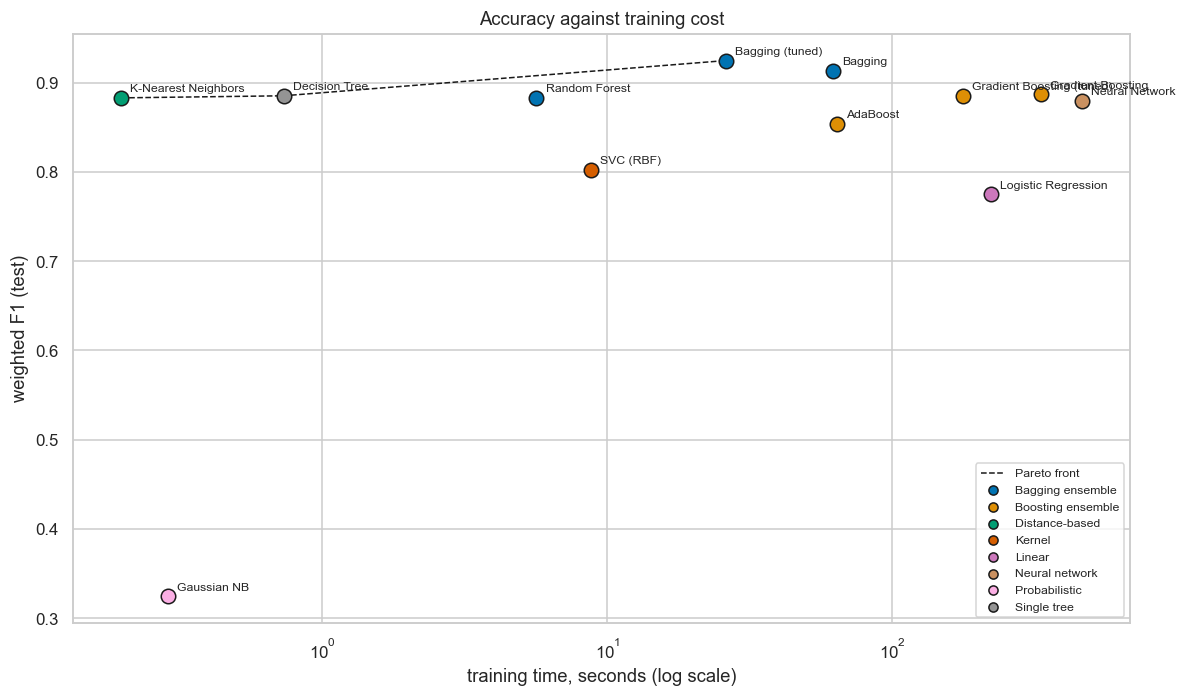

Pareto-optimal: K-Nearest Neighbors, Decision Tree, Bagging (tuned)


,F1 (weighted),Train time (s),Predict time (s)
Model,,,
K-Nearest Neighbors,0.883,0.197,8.165
Gaussian NB,0.324,0.287,0.259
Decision Tree,0.885,0.732,0.011
Random Forest,0.883,5.640,0.508
SVC (RBF),0.802,8.749,31.980
Bagging (tuned),0.925,26.016,0.843
Bagging,0.913,61.958,1.531
AdaBoost,0.854,63.796,1.525
Gradient Boosting (tuned),0.885,176.033,0.851


In [19]:
t = table.set_index('Model')
fig, ax = plt.subplots(figsize=(11, 6.5))
fam_colors = dict(zip(sorted(t['Family'].unique()), sns.color_palette('colorblind', t['Family'].nunique())))
for n, r in t.iterrows():
    ax.scatter(r['Train time (s)'], r['F1 (weighted)'], s=90, color=fam_colors[r['Family']], edgecolor='k', zorder=3)
    ax.annotate(n, (r['Train time (s)'], r['F1 (weighted)']), textcoords='offset points', xytext=(6, 4), fontsize=8)
front = t.sort_values('Train time (s)')
front = front[front['F1 (weighted)'] >= front['F1 (weighted)'].cummax()]
ax.plot(front['Train time (s)'], front['F1 (weighted)'], 'k--', lw=1, label='Pareto front')
for f, c in fam_colors.items():
    ax.scatter([], [], color=c, edgecolor='k', label=f)
ax.set_xscale('log'); ax.set_xlabel('training time, seconds (log scale)'); ax.set_ylabel('weighted F1 (test)')
ax.set_title('Accuracy against training cost')
ax.legend(fontsize=8, loc='lower right')
plt.tight_layout(); save(fig, 'cls_07_f1_vs_time.png'); plt.show()
print('Pareto-optimal:', ', '.join(front.index))
t[['F1 (weighted)', 'Train time (s)', 'Predict time (s)']].sort_values('Train time (s)').round(3)

> **Observation (write in your own words):** Is the most accurate model worth its training time here? Which model would you pick if training had to finish in under a minute?
>
> _…_

## 1.8 Families of algorithms, and Part A vs Part B
The 10 algorithms grouped by how they learn.

saved results\figures\comparative\cls_08_families.png


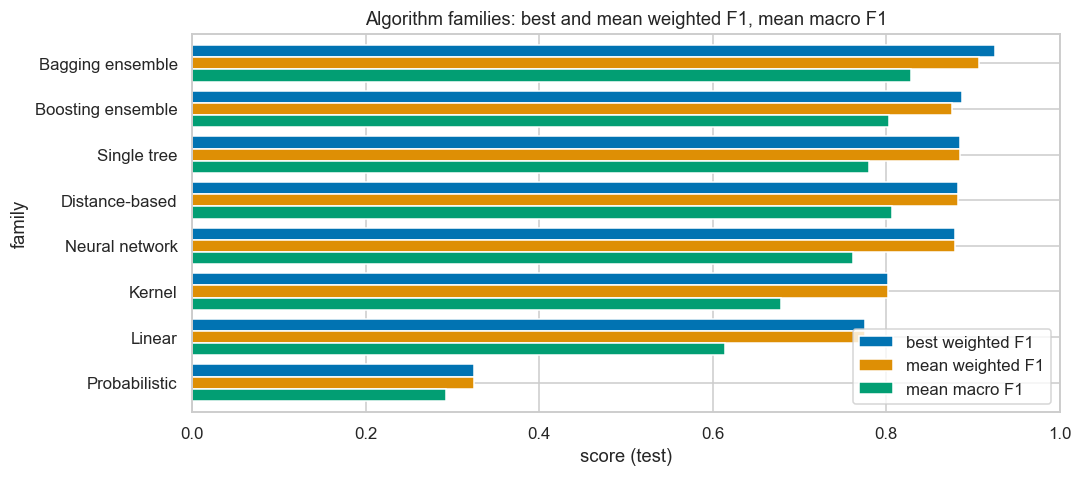

,models,configs,best_F1w,mean_F1w,mean_F1m,mean_AUC,mean_train_s
Family,,,,,,,
Bagging ensemble,"Bagging (tuned), Bagging, Random Forest",3,0.9249,0.9072,0.8280,0.9882,31.2047
Boosting ensemble,"Gradient Boosting, Gradient Boosting (tuned), ...",3,0.8871,0.8754,0.8036,0.9856,190.7152
Single tree,Decision Tree,1,0.8854,0.8854,0.7799,0.9166,0.7321
Distance-based,K-Nearest Neighbors,1,0.8831,0.8831,0.8064,0.9522,0.1971
Neural network,Neural Network,1,0.8795,0.8795,0.7621,0.9607,462.5948
Kernel,SVC (RBF),1,0.8024,0.8024,0.6791,0.9374,8.7489
Linear,Logistic Regression,1,0.7751,0.7751,0.6147,0.9637,221.6087
Probabilistic,Gaussian NB,1,0.3243,0.3243,0.2927,0.9159,0.2873


In [20]:
fam = table.groupby('Family').agg(models=('Model', lambda s: ', '.join(s)), configs=('Model', 'size'),
                                  best_F1w=('F1 (weighted)', 'max'), mean_F1w=('F1 (weighted)', 'mean'),
                                  mean_F1m=('F1 (macro)', 'mean'), mean_AUC=('ROC-AUC (OvR)', 'mean'),
                                  mean_train_s=('Train time (s)', 'mean')).sort_values('best_F1w', ascending=False)
fam.to_csv(os.path.join(OUT, 'classification_families.csv'))
fig, ax = plt.subplots(figsize=(10, 4.5))
fam[['best_F1w', 'mean_F1w', 'mean_F1m']].plot(kind='barh', ax=ax, width=0.8)
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_xlabel('score (test)'); ax.set_ylabel('family')
ax.set_title('Algorithm families: best and mean weighted F1, mean macro F1')
ax.legend(['best weighted F1', 'mean weighted F1', 'mean macro F1'], loc='lower right')
plt.tight_layout(); save(fig, 'cls_08_families.png'); plt.show()
fam.round(4)

In [21]:
parts = table[~table['Model'].str.contains('tuned')].groupby('Part')[METRICS + ['Train time (s)']].mean()
parts.index = ['Part A (LR, KNN, NB, DT, SVC)', 'Part B (RF, AdaBoost, GB, Bagging, MLP)']
parts.to_csv(os.path.join(OUT, 'classification_part_a_vs_b.csv'))
parts.round(4)

,Accuracy,Precision (w),Recall (w),F1 (weighted),F1 (macro),ROC-AUC (OvR),Train time (s)
"Part A (LR, KNN, NB, DT, SVC)",0.7379,0.8029,0.7379,0.7341,0.6346,0.9371,46.3148
"Part B (RF, AdaBoost, GB, Bagging, MLP)",0.8819,0.9172,0.8819,0.8835,0.7989,0.9801,185.2610


> **Observation (write in your own words):** Why do the ensemble families come out ahead of a single tree on machines the models never saw? Where does the linear model fall short?
>
> _…_

## 1.9 Base vs tuned
The improvement from hyperparameter tuning, per metric. Tuning used grouped 3-fold CV on the training set only (`03_classification_1.ipynb`); the test set is scored once.

saved results\figures\comparative\cls_09_tuning_delta.png


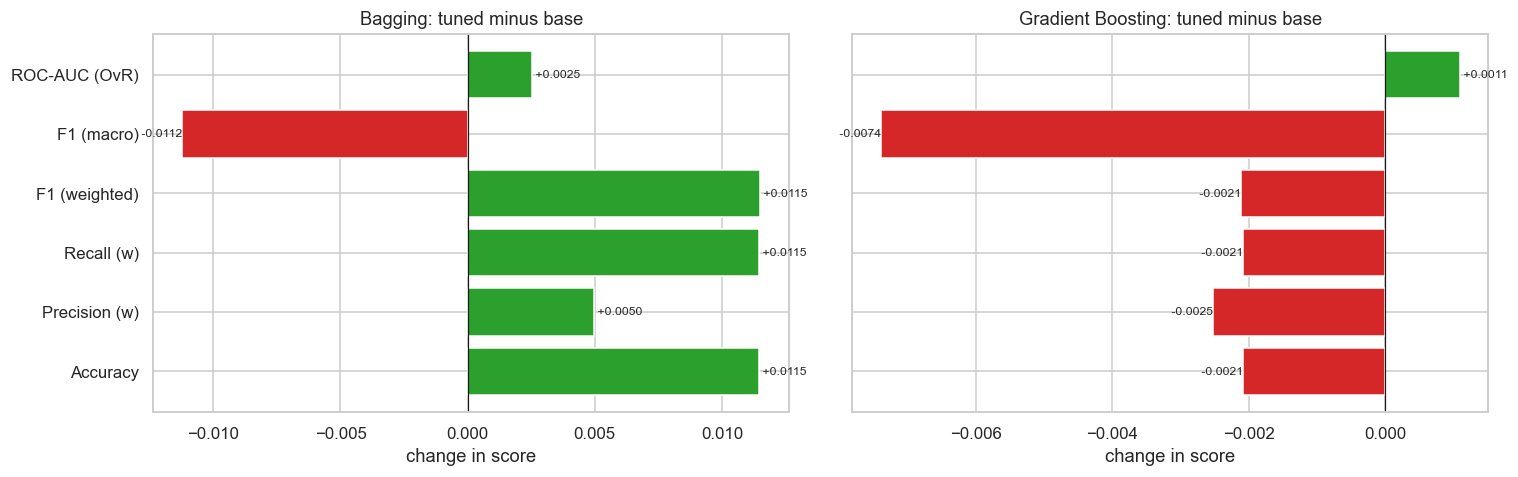

Algorithm,Bagging,Gradient Boosting
Metric,,
Accuracy,0.0115,-0.0021
Precision (w),0.0050,-0.0025
Recall (w),0.0115,-0.0021
F1 (weighted),0.0115,-0.0021
F1 (macro),-0.0112,-0.0074
ROC-AUC (OvR),0.0025,0.0011


In [22]:
pairs = [('Bagging', 'Bagging (tuned)'), ('Gradient Boosting', 'Gradient Boosting (tuned)')]
rows = []
for base, tuned in pairs:
    for m in METRICS:
        b, tu = t.loc[base, m], t.loc[tuned, m]
        rows.append({'Algorithm': base, 'Metric': m, 'Base': b, 'Tuned': tu, 'Change': tu - b})
tune = pd.DataFrame(rows)
tune.to_csv(os.path.join(OUT, 'classification_tuning_delta.csv'), index=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, (base, _) in zip(axes, pairs):
    d = tune[tune['Algorithm'] == base].set_index('Metric')['Change']
    ax.barh(d.index, d.values, color=['tab:green' if v >= 0 else 'tab:red' for v in d.values])
    ax.axvline(0, color='k', lw=0.8); ax.set_title(f'{base}: tuned minus base'); ax.set_xlabel('change in score')
    for i, v in enumerate(d.values):
        ax.text(v, i, f' {v:+.4f}', va='center', ha='left' if v >= 0 else 'right', fontsize=8)
plt.tight_layout(); save(fig, 'cls_09_tuning_delta.png'); plt.show()
tune.pivot(index='Metric', columns='Algorithm', values='Change').reindex(METRICS).round(4)

> **Observation (write in your own words):** Which metric did tuning improve, and did any get worse? Is the change larger than the uncertainty in Section 1.11?
>
> _…_

## 1.10 Stability: 5-fold cross-validation of the top two
Training set only. **Grouped** folds keep every machine on one side (as the test split does); **stratified** folds let a machine sit in both training and validation folds.

grouped by machine   Bagging (tuned)          F1w 0.5203 ± 0.3107  (26s)


grouped by machine   Bagging                  F1w 0.5186 ± 0.3105  (8s)


stratified           Bagging (tuned)          F1w 0.9817 ± 0.0009  (16s)


stratified           Bagging                  F1w 0.9827 ± 0.0007  (8s)


saved results\figures\comparative\cls_10_cv_stability.png


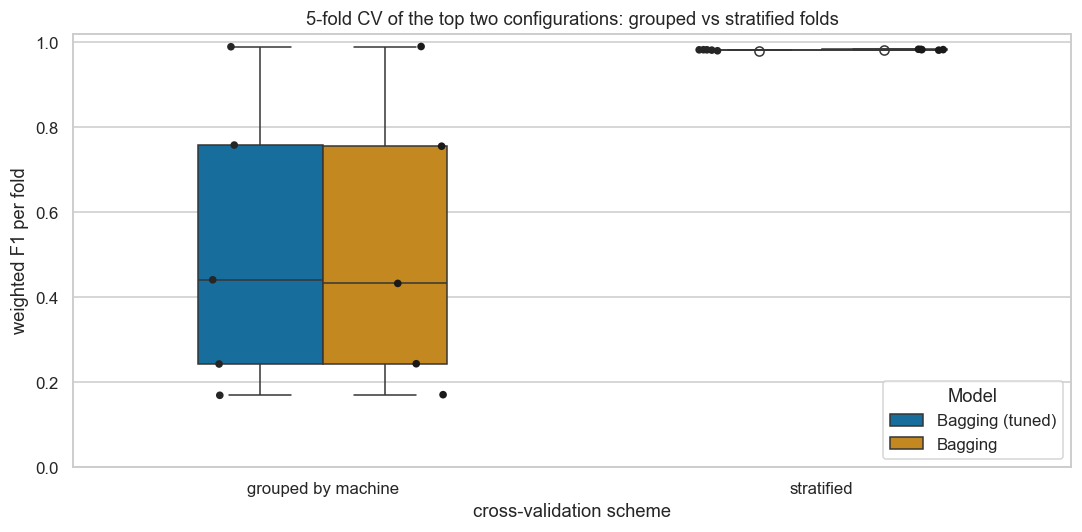

F1 (weighted)         F1 (macro)         Accuracy        
                                            mean     std       mean     std     mean     std
Model           CV                                                                          
Bagging         grouped by machine        0.5186  0.3472     0.1690  0.0225   0.5121  0.3238
                stratified                0.9827  0.0008     0.9443  0.0050   0.9823  0.0009
Bagging (tuned) grouped by machine        0.5203  0.3474     0.1697  0.0232   0.5119  0.3245
                stratified                0.9817  0.0010     0.9427  0.0051   0.9813  0.0010

In [23]:
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, cross_validate
top2 = table['Model'].head(2).tolist()
cv_rows = []
for kind, cv in [('grouped by machine', StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)),
                 ('stratified', StratifiedKFold(n_splits=5, shuffle=True, random_state=42))]:
    for n in top2:
        est, data, sw = CONFIGS[n][0], CONFIGS[n][3], CONFIGS[n][4]
        Xc = X_train_df if data == 'df' else X_tr
        params = {'sample_weight': compute_sample_weight(class_weight='balanced', y=y_tr)} if sw else None
        t0 = time.time()
        res = cross_validate(clone(est), Xc, y_tr, groups=groups_tr if kind.startswith('grouped') else None, cv=cv,
                             scoring=['f1_weighted', 'f1_macro', 'accuracy'], n_jobs=5, params=params)
        for k in range(5):
            cv_rows.append({'Model': n, 'CV': kind, 'fold': k + 1, 'F1 (weighted)': res['test_f1_weighted'][k],
                            'F1 (macro)': res['test_f1_macro'][k], 'Accuracy': res['test_accuracy'][k]})
        print(f'{kind:20s} {n:24s} F1w {res["test_f1_weighted"].mean():.4f} ± {res["test_f1_weighted"].std():.4f}  ({time.time() - t0:.0f}s)')
cvf = pd.DataFrame(cv_rows)
cvf.to_csv(os.path.join(OUT, 'classification_cv5_folds.csv'), index=False)
cv_sum = cvf.groupby(['Model', 'CV'])[['F1 (weighted)', 'F1 (macro)', 'Accuracy']].agg(['mean', 'std'])
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=cvf, x='CV', y='F1 (weighted)', hue='Model', ax=ax, width=0.5)
sns.stripplot(data=cvf, x='CV', y='F1 (weighted)', hue='Model', dodge=True, ax=ax, color='k', size=5, legend=False)
ax.set_ylim(0, 1.02); ax.set_xlabel('cross-validation scheme'); ax.set_ylabel('weighted F1 per fold')
ax.set_title('5-fold CV of the top two configurations: grouped vs stratified folds')
plt.tight_layout(); save(fig, 'cls_10_cv_stability.png'); plt.show()
cv_sum.round(4)

> **Observation (write in your own words):** Why are the grouped folds so much more spread out than the stratified ones? Which number is the honest estimate for a new machine?
>
> _…_

## 1.11 Is the gap real? Bootstrap intervals and McNemar's test
**Bootstrap:** the test set is resampled 1,000 times (with replacement) and weighted F1 recomputed; the 2.5th–97.5th percentiles give a 95% interval per model.
**McNemar:** compares the best model with each other model on the same test flows, counting only the flows where exactly one of the two is right. A small p-value (< 0.05) means the difference in errors is unlikely to be chance.

saved results\figures\comparative\cls_11_bootstrap_ci.png


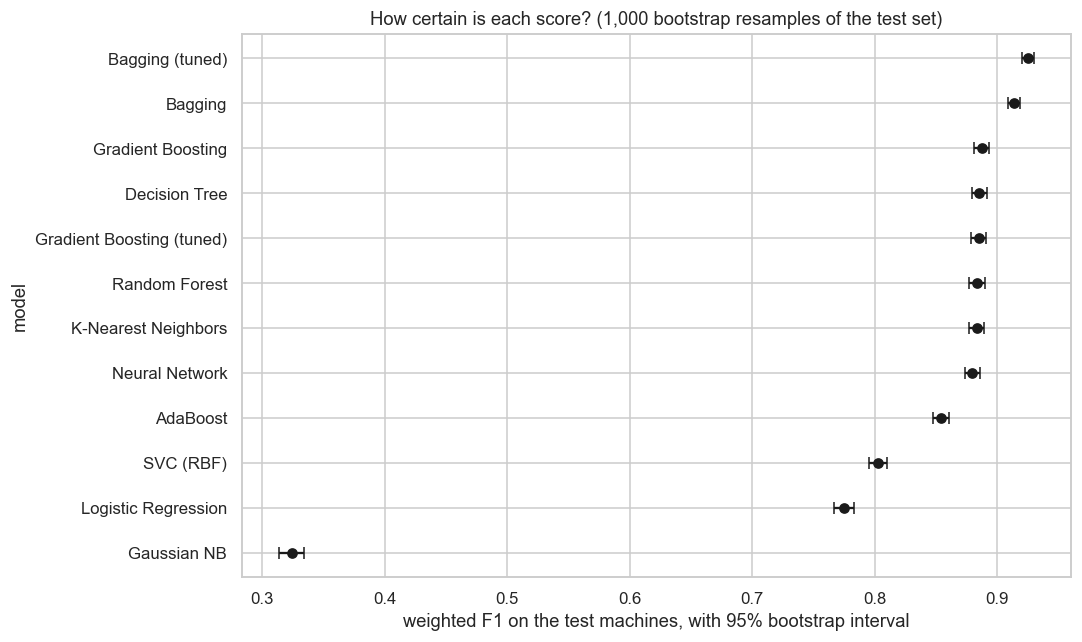

,Model,F1 (weighted),CI low (2.5%),CI high (97.5%),bootstrap std
0,Bagging (tuned),0.9249,0.9203,0.9297,0.0024
1,Bagging,0.9134,0.9084,0.9185,0.0026
2,Gradient Boosting,0.8871,0.8808,0.8932,0.0031
3,Decision Tree,0.8854,0.8793,0.8915,0.0032
4,Gradient Boosting (tuned),0.8850,0.8788,0.8910,0.0032
5,Random Forest,0.8833,0.8771,0.8895,0.0032
6,K-Nearest Neighbors,0.8831,0.8769,0.8895,0.0032
7,Neural Network,0.8795,0.8736,0.8855,0.0032
8,AdaBoost,0.8540,0.8475,0.8604,0.0034
9,SVC (RBF),0.8024,0.7954,0.8097,0.0039


,Compared with,only Bagging (tuned) right,only other right,p-value (exact McNemar),significant at 0.05
0,Bagging,155,28,0.0,True
1,Gradient Boosting,513,120,0.0,True
2,Decision Tree,575,130,0.0,True
3,Gradient Boosting (tuned),522,106,0.0,True
4,Random Forest,528,114,0.0,True
5,K-Nearest Neighbors,576,137,0.0,True
6,Neural Network,609,120,0.0,True
7,AdaBoost,955,169,0.0,True
8,SVC (RBF),1714,110,0.0,True
9,Logistic Regression,1923,93,0.0,True


In [24]:
from scipy.stats import binomtest
B = 1000
rs = np.random.RandomState(42)
boot_idx = [rs.randint(0, len(y_te), len(y_te)) for _ in range(B)]
lab_code = {c: i for i, c in enumerate(LABELS)}
yc = np.array([lab_code[v] for v in y_te])


def f1w_fast(yt, yp, k=len(LABELS)):
    cm = np.bincount(yt * k + yp, minlength=k * k).reshape(k, k)
    tp = np.diag(cm); sup = cm.sum(1); prd = cm.sum(0)
    f1 = np.divide(2 * tp, sup + prd, out=np.zeros(k), where=(sup + prd) > 0)
    return float((f1 * sup).sum() / sup.sum())


ci_rows = []
for n in table['Model']:
    pc = np.array([lab_code.get(v, 0) for v in RUN[n]['pred']])
    vals = np.array([f1w_fast(yc[i], pc[i]) for i in boot_idx])
    ci_rows.append({'Model': n, 'F1 (weighted)': f1w_fast(yc, pc), 'CI low (2.5%)': np.percentile(vals, 2.5),
                    'CI high (97.5%)': np.percentile(vals, 97.5), 'bootstrap std': vals.std()})
ci = pd.DataFrame(ci_rows)
ci.to_csv(os.path.join(OUT, 'classification_bootstrap_ci.csv'), index=False)

ok_w = RUN[WINNER]['pred'] == y_te
mc_rows = []
for n in table['Model'][1:]:
    ok_o = RUN[n]['pred'] == y_te
    b, c = int((ok_w & ~ok_o).sum()), int((~ok_w & ok_o).sum())
    mc_rows.append({'Compared with': n, f'only {WINNER} right': b, 'only other right': c,
                    'p-value (exact McNemar)': binomtest(min(b, c), b + c, 0.5).pvalue if b + c else 1.0})
mcn = pd.DataFrame(mc_rows)
mcn['significant at 0.05'] = mcn['p-value (exact McNemar)'] < 0.05
mcn.to_csv(os.path.join(OUT, 'classification_mcnemar.csv'), index=False)

fig, ax = plt.subplots(figsize=(10, 6))
cs = ci.iloc[::-1]
ax.errorbar(cs['F1 (weighted)'], cs['Model'], xerr=[cs['F1 (weighted)'] - cs['CI low (2.5%)'], cs['CI high (97.5%)'] - cs['F1 (weighted)']],
            fmt='o', capsize=4, color='k')
ax.set_xlabel('weighted F1 on the test machines, with 95% bootstrap interval'); ax.set_ylabel('model')
ax.set_title('How certain is each score? (1,000 bootstrap resamples of the test set)')
plt.tight_layout(); save(fig, 'cls_11_bootstrap_ci.png'); plt.show()
display(ci.round(4))
mcn.round(5)

> **Observation (write in your own words):** Which differences between neighbouring models are within the uncertainty, and which are clearly real?
>
> _…_

## 1.12 Summary of the classification comparison

In [25]:
T = table.set_index('Model')
cls_summary = pd.DataFrame([{'Question': f'Best {m}', 'Model': T[m].idxmax(), 'Value': T[m].max()} for m in METRICS] +
                           [{'Question': 'Fastest to train (s)', 'Model': T['Train time (s)'].idxmin(), 'Value': T['Train time (s)'].min()},
                            {'Question': 'Best mean rank over the six metrics', 'Model': ranks.index[0], 'Value': ranks['Mean rank'].iloc[0]}])
cls_summary.to_csv(os.path.join(OUT, 'classification_summary.csv'), index=False)
cls_summary.round(4)

,Question,Model,Value
0,Best Accuracy,Bagging (tuned),0.9217
1,Best Precision (w),Bagging (tuned),0.9386
2,Best Recall (w),Bagging (tuned),0.9217
3,Best F1 (weighted),Bagging (tuned),0.9249
4,Best F1 (macro),Bagging,0.8463
5,Best ROC-AUC (OvR),Gradient Boosting (tuned),0.9923
6,Fastest to train (s),K-Nearest Neighbors,0.1971
7,Best mean rank over the six metrics,Bagging (tuned),1.5000


> **Observation (write in your own words):** Which model would you deploy, and why? Mention at least two of: weighted vs macro F1, per-class results, training cost, cross-validation, and the bootstrap/McNemar results.
>
> _…_

# Part 2 · Clustering: K-Means vs Agglomerative

## 2.0 Data preparation (identical to `clustering.ipynb`)
30,000 deduplicated flows, labels set aside, engineered features, numbers standardised and categories one-hot encoded. Agglomerative clustering needs the full pairwise-distance matrix, so **every algorithm is scored on the same 6,000-flow subset** (`agg_idx`).

Besides the two required algorithms, four others are run **for reference only**: MiniBatch K-Means, Gaussian Mixture, BIRCH and DBSCAN. They are marked as *extra* in every table.

In [26]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score, normalized_mutual_info_score

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["figure.dpi"] = 110
N_KMEANS = 30_000   # flows used to fit K-Means
N_AGG = 6_000       # agglomerative clustering is O(n^2) in memory: a subset of the K-Means sample
N_TSNE = 3_000
from sklearn.cluster import MiniBatchKMeans, Birch, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import homogeneity_score, completeness_score, v_measure_score
from sklearn.neighbors import NearestNeighbors

In [27]:
DATA_PATH = os.path.join(ROOT, 'data', 'raw', 'TON_IoT', 'train_test_network.csv')
raw = pd.read_csv(DATA_PATH, low_memory=False)
df_c = raw.drop_duplicates(ignore_index=True)
print('after dropping duplicates:', df_c.shape)

after dropping duplicates: (190474, 44)


In [28]:
# Columns that identify a machine or hold free text. A model that sees them can memorise
# which testbed host ran which attack instead of learning what the traffic looks like.
IDENTIFIERS = ["src_ip", "dst_ip", "src_port"]
FREE_TEXT = ["dns_query", "ssl_subject", "ssl_issuer", "http_uri", "http_user_agent", "http_orig_mime_types",
             "http_resp_mime_types", "http_trans_depth", "http_version", "weird_addl"]
# `label` is 0 exactly when `type` is normal, so it is the answer in disguise.
TARGET, LEAKY_TARGET = "type", "label"

# Heavy-tailed counts: log1p squeezes values that span several orders of magnitude.
LOG_COLS = ["duration", "src_bytes", "dst_bytes", "missed_bytes", "src_pkts", "dst_pkts", "src_ip_bytes",
            "dst_ip_bytes", "http_request_body_len", "http_response_body_len"]
# Low-cardinality codes and flags, one-hot encoded. Numeric codes such as dns_qtype are labels, not quantities.
CAT_COLS = ["proto", "service", "conn_state", "dns_AA", "dns_RD", "dns_RA", "dns_rejected", "ssl_version",
            "ssl_cipher", "ssl_resumed", "ssl_established", "http_method", "weird_name", "weird_notice",
            "dns_qtype", "dns_rcode", "dns_qclass", "http_status_code", "dst_port_bucket"]


def build_features(d, top_ports):
    """Engineered feature table. `top_ports` must come from the training rows only."""
    X = pd.DataFrame(index=d.index)
    for c in LOG_COLS:
        X[c] = np.log1p(d[c].clip(lower=0))
    # engineered: average packet size each way (scans and floods send tiny, uniform packets)
    X["bytes_per_src_pkt"] = np.log1p(d["src_bytes"] / d["src_pkts"].replace(0, np.nan)).fillna(0)
    X["bytes_per_dst_pkt"] = np.log1p(d["dst_bytes"] / d["dst_pkts"].replace(0, np.nan)).fillna(0)
    # engineered: did the other side answer at all? (S0/REJ scans often get no reply)
    X["has_reply"] = (d["dst_pkts"] > 0).astype(int)
    # engineered: the ten most common destination ports keep their number, the rest become "other"
    port = d["dst_port"].where(d["dst_port"].isin(top_ports))
    X["dst_port_bucket"] = port.map(lambda p: "other" if pd.isna(p) else str(int(p)))
    for c in CAT_COLS:
        if c != "dst_port_bucket":
            X[c] = d[c].astype(str)
    return X

In [29]:
sample = df_c.sample(n=min(N_KMEANS, len(df_c)), random_state=RANDOM_STATE).reset_index(drop=True)
truth = sample[TARGET].values                     # kept aside for interpretation only
top_ports = sample["dst_port"].value_counts().head(10).index
F = build_features(sample, top_ports)
num_cols = [c for c in F.columns if pd.api.types.is_numeric_dtype(F[c])]
cat_cols = [c for c in F.columns if c not in num_cols]
pre = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50, sparse_output=False), cat_cols),
])
X = pre.fit_transform(F)
print("feature matrix:", X.shape)
agg_idx = np.random.RandomState(RANDOM_STATE).choice(len(X), N_AGG, replace=False)

feature matrix: (30000, 87)


## 2.1 Choosing k (same rule as `clustering.ipynb`)
The elbow of the K-Means inertia curve; every algorithm that needs a number of clusters uses this k.

In [30]:
ks = range(2, 13)
inertia = [KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X).inertia_ for k in ks]
line = np.interp(list(ks), [ks[0], ks[-1]], [inertia[0], inertia[-1]])
K_BEST = int(list(ks)[int(np.argmax(line - np.array(inertia)))])
print('k chosen by the elbow:', K_BEST)

k chosen by the elbow: 6


## 2.2 Fit every algorithm (timed)
* **K-Means**: fitted on all 30,000 flows (as in `clustering.ipynb`), labels read off the 6,000-flow subset.
* **Agglomerative**: ward, complete, average and single linkage on the 6,000 flows.
* *Extra*: MiniBatch K-Means and Gaussian Mixture (diagonal covariance) on 30,000 flows; BIRCH and DBSCAN on the 6,000 flows. DBSCAN chooses its own number of clusters: `eps` is the 95th percentile of each flow's distance to its 10th neighbour, and the flows it calls noise are left out of its internal scores.

In [31]:
Xa = X[agg_idx]
truth_a = truth[agg_idx]
CLU_RUN = {}


def timed(fn):
    t0 = time.perf_counter(); out = fn(); return out, time.perf_counter() - t0


km, s = timed(lambda: KMeans(n_clusters=K_BEST, n_init=20, random_state=RANDOM_STATE).fit(X))
CLU_RUN['K-Means'] = {'labels': km.labels_[agg_idx], 'time': s, 'required': True}
for lk in ['ward', 'complete', 'average', 'single']:
    lab, s = timed(lambda: AgglomerativeClustering(n_clusters=K_BEST, linkage=lk).fit_predict(Xa))
    CLU_RUN[f'Agglomerative ({lk})'] = {'labels': lab, 'time': s, 'required': True}
mb, s = timed(lambda: MiniBatchKMeans(n_clusters=K_BEST, n_init=10, random_state=RANDOM_STATE, batch_size=2048).fit(X))
CLU_RUN['MiniBatch K-Means'] = {'labels': mb.predict(Xa), 'time': s, 'required': False}
gm, s = timed(lambda: GaussianMixture(n_components=K_BEST, covariance_type='diag', random_state=RANDOM_STATE, reg_covar=1e-4).fit(X))
CLU_RUN['Gaussian Mixture'] = {'labels': gm.predict(Xa), 'time': s, 'required': False}
br, s = timed(lambda: Birch(n_clusters=K_BEST, threshold=0.5).fit(Xa))
CLU_RUN['BIRCH'] = {'labels': br.labels_, 'time': s, 'required': False}
kdist = np.sort(NearestNeighbors(n_neighbors=10).fit(Xa).kneighbors(Xa)[0][:, -1])
EPS = float(np.percentile(kdist, 95))
db, s = timed(lambda: DBSCAN(eps=EPS, min_samples=10).fit(Xa))
CLU_RUN['DBSCAN'] = {'labels': db.labels_, 'time': s, 'required': False}
print(f'DBSCAN eps = {EPS:.3f}: {len(set(db.labels_) - {-1})} clusters, {np.mean(db.labels_ == -1):.1%} of flows marked noise')
for n, r in CLU_RUN.items():
    print(f'{n:26s} {r["time"]:6.2f}s  cluster sizes {np.bincount(r["labels"][r["labels"] >= 0]).tolist()}')

DBSCAN eps = 1.476: 23 clusters, 4.0% of flows marked noise
K-Means                      1.33s  cluster sizes [1311, 2130, 1066, 350, 3, 1140]
Agglomerative (ward)         4.91s  cluster sizes [1259, 1065, 3, 1108, 2224, 341]
Agglomerative (complete)     4.78s  cluster sizes [5938, 56, 1, 2, 2, 1]
Agglomerative (average)      5.08s  cluster sizes [4, 3, 5989, 1, 2, 1]
Agglomerative (single)       3.86s  cluster sizes [3, 2, 5990, 1, 3, 1]
MiniBatch K-Means            0.46s  cluster sizes [1314, 1130, 612, 2128, 349, 467]
Gaussian Mixture             7.97s  cluster sizes [2117, 1312, 600, 1129, 360, 482]
BIRCH                        0.71s  cluster sizes [4707, 1230, 4, 56, 2, 1]
DBSCAN                       0.55s  cluster sizes [1108, 1002, 1698, 275, 399, 339, 155, 141, 119, 90, 70, 40, 44, 16, 93, 47, 12, 35, 19, 23, 13, 15, 10]


## 2.3 Comparison table
Internal scores (no labels): **Silhouette ↑**, **Davies-Bouldin ↓**, **Calinski-Harabasz ↑**.
External scores, computed **after** fitting with the true traffic type: **ARI**, **NMI**, homogeneity, completeness and **purity** (share of flows that belong to their cluster's most common type).

In [32]:
def purity(y, lab):
    ct = pd.crosstab(lab, y)
    return ct.max(axis=1).sum() / ct.values.sum()


clu_rows = []
for n, r in CLU_RUN.items():
    lab = r['labels']; keep = lab >= 0
    Xi, li, yi = Xa[keep], lab[keep], truth_a[keep]
    two = len(set(li)) > 1          # internal scores need at least two clusters
    clu_rows.append({'Algorithm': n, 'Required': 'yes' if r['required'] else 'extra', 'Clusters': len(set(li)),
                     'Silhouette ↑': silhouette_score(Xi, li) if two else np.nan,
                     'Davies-Bouldin ↓': davies_bouldin_score(Xi, li) if two else np.nan,
                     'Calinski-Harabasz ↑': calinski_harabasz_score(Xi, li) if two else np.nan,
                     'ARI ↑': adjusted_rand_score(yi, li), 'NMI ↑': normalized_mutual_info_score(yi, li),
                     'Homogeneity ↑': homogeneity_score(yi, li), 'Completeness ↑': completeness_score(yi, li),
                     'Purity ↑': purity(yi, li), 'Largest cluster share': np.bincount(li).max() / len(li),
                     'Noise share': 1 - keep.mean(), 'Fit time (s)': r['time']})
clu = pd.DataFrame(clu_rows).set_index('Algorithm')
clu.to_csv(os.path.join(OUT, 'clustering_comparison.csv'))
HIGH = ['Silhouette ↑', 'Calinski-Harabasz ↑', 'ARI ↑', 'NMI ↑', 'Homogeneity ↑', 'Completeness ↑', 'Purity ↑']
best_row = {c: clu[c].idxmax() for c in HIGH} | {'Davies-Bouldin ↓': clu['Davies-Bouldin ↓'].idxmin()}
print('best on each metric:'); print(pd.Series(best_row).to_string())
(clu.style.format('{:.4f}', subset=HIGH + ['Davies-Bouldin ↓', 'Largest cluster share', 'Noise share'])
    .format('{:.2f}', subset=['Fit time (s)'])
    .highlight_max(subset=HIGH, color='#c7e9c0').highlight_min(subset=['Davies-Bouldin ↓'], color='#c7e9c0'))

best on each metric:
Silhouette ↑           Agglomerative (average)
Calinski-Harabasz ↑                     DBSCAN
ARI ↑                                   DBSCAN
NMI ↑                                   DBSCAN
Homogeneity ↑                           DBSCAN
Completeness ↑                           BIRCH
Purity ↑                                DBSCAN
Davies-Bouldin ↓        Agglomerative (single)


,Required,Clusters,Silhouette ↑,Davies-Bouldin ↓,Calinski-Harabasz ↑,ARI ↑,NMI ↑,Homogeneity ↑,Completeness ↑,Purity ↑,Largest cluster share,Noise share,Fit time (s)
Algorithm,,,,,,,,,,,,,
K-Means,yes,6,0.4741,0.7426,2953.6417,0.2594,0.4216,0.3562,0.5163,0.4587,0.3550,0.0000,1.33
Agglomerative (ward),yes,6,0.4622,0.7524,2844.7651,0.2487,0.4162,0.3507,0.5119,0.4567,0.3707,0.0000,4.91
Agglomerative (complete),yes,6,0.5813,0.2994,490.8967,0.0000,0.0086,0.0044,0.1538,0.2263,0.9897,0.0000,4.78
Agglomerative (average),yes,6,0.6799,0.3657,386.1760,-0.0005,0.0030,0.0015,0.2026,0.2235,0.9982,0.0000,5.08
Agglomerative (single),yes,6,0.6798,0.2671,384.7117,-0.0005,0.0026,0.0013,0.1942,0.2233,0.9983,0.0000,3.86
MiniBatch K-Means,extra,6,0.4908,0.7809,1445.0281,0.2443,0.4325,0.3775,0.5064,0.4598,0.3547,0.0000,0.46
Gaussian Mixture,extra,6,0.4889,0.8003,1427.4698,0.2453,0.4337,0.3789,0.5070,0.4618,0.3528,0.0000,7.97
BIRCH,extra,6,0.4066,0.5104,1290.0664,0.0954,0.2436,0.1538,0.5855,0.3167,0.7845,0.0000,0.71
DBSCAN,extra,23,0.6241,0.5179,3167.3520,0.3005,0.5408,0.5440,0.5377,0.5659,0.2946,0.0395,0.55


In [33]:
# the two required algorithms only: K-Means vs the best Agglomerative linkage
req = clu[clu['Required'] == 'yes']
usable = req[req['Largest cluster share'] < 0.9]
best_agg = usable.filter(like='Agglomerative', axis=0)['Silhouette ↑'].idxmax()
head2 = clu.loc[['K-Means', best_agg]]
head2.to_csv(os.path.join(OUT, 'clustering_kmeans_vs_agglomerative.csv'))
print('Agglomerative linkage used for the head-to-head (no cluster with 90%+ of flows, best silhouette):', best_agg)
head2.drop(columns=['Required', 'Noise share']).T.round(4)

Agglomerative linkage used for the head-to-head (no cluster with 90%+ of flows, best silhouette): Agglomerative (ward)


Algorithm,K-Means,Agglomerative (ward)
Clusters,6.0000,6.0000
Silhouette ↑,0.4741,0.4622
Davies-Bouldin ↓,0.7426,0.7524
Calinski-Harabasz ↑,2953.6417,2844.7651
ARI ↑,0.2594,0.2487
NMI ↑,0.4216,0.4162
Homogeneity ↑,0.3562,0.3507
Completeness ↑,0.5163,0.5119
Purity ↑,0.4587,0.4567
Largest cluster share,0.3550,0.3707


> **Observation (write in your own words):** Which algorithm wins on the internal scores, and which on the label-based scores? Why can a linkage with a high silhouette still be a poor clustering (look at the largest-cluster share)?
>
> _…_

## 2.4 Do the metrics agree on k? Sweep k = 2 … 10
K-Means, Agglomerative (ward) and two extras, each fitted on the same 6,000 flows for every k.

saved results\figures\comparative\clu_01_k_sweep.png


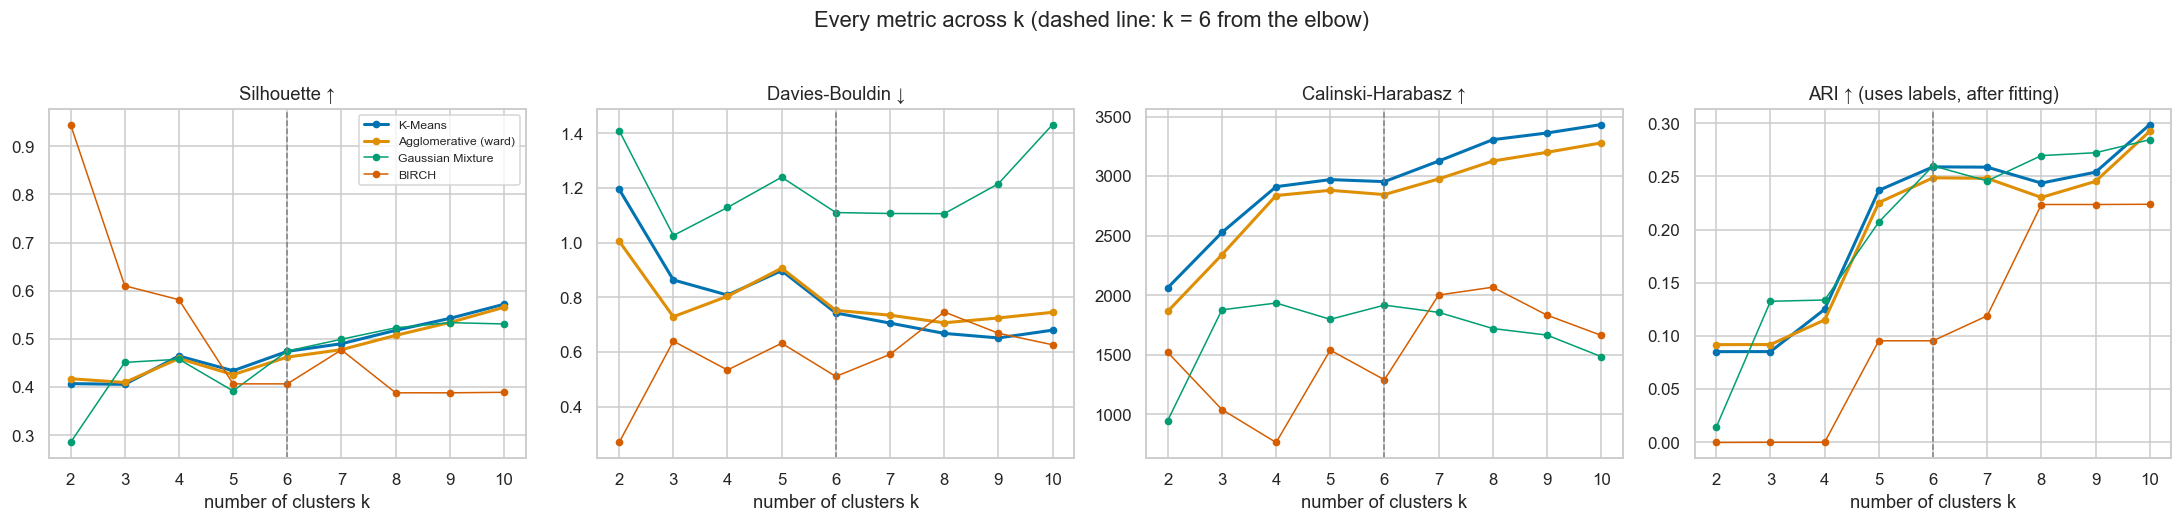

,Silhouette ↑,Davies-Bouldin ↓,Calinski-Harabasz ↑,ARI ↑
best k by →,,,,
Agglomerative (ward),10,8,10,10
BIRCH,2,2,8,10
Gaussian Mixture,9,3,4,10
K-Means,10,9,10,10


In [34]:
SWEEP = {'K-Means': lambda k: KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(Xa),
         'Agglomerative (ward)': lambda k: AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(Xa),
         'Gaussian Mixture': lambda k: GaussianMixture(n_components=k, covariance_type='diag', random_state=RANDOM_STATE, reg_covar=1e-4).fit(Xa).predict(Xa),
         'BIRCH': lambda k: Birch(n_clusters=k, threshold=0.5).fit_predict(Xa)}
sw_rows = []
for n, fn in SWEEP.items():
    for k in range(2, 11):
        lab = fn(k)
        sw_rows.append({'Algorithm': n, 'k': k, 'Silhouette ↑': silhouette_score(Xa, lab), 'Davies-Bouldin ↓': davies_bouldin_score(Xa, lab),
                        'Calinski-Harabasz ↑': calinski_harabasz_score(Xa, lab), 'ARI ↑': adjusted_rand_score(truth_a, lab)})
sweep = pd.DataFrame(sw_rows)
sweep.to_csv(os.path.join(OUT, 'clustering_k_sweep.csv'), index=False)
fig, axes = plt.subplots(1, 4, figsize=(20, 4.6))
for ax, m in zip(axes, ['Silhouette ↑', 'Davies-Bouldin ↓', 'Calinski-Harabasz ↑', 'ARI ↑']):
    for n in SWEEP:
        d = sweep[sweep['Algorithm'] == n]
        ax.plot(d['k'], d[m], 'o-', label=n, lw=2 if n in ('K-Means', 'Agglomerative (ward)') else 1, ms=4)
    ax.axvline(K_BEST, color='grey', ls='--', lw=1)
    ax.set_title(m + (' (uses labels, after fitting)' if m == 'ARI ↑' else '')); ax.set_xlabel('number of clusters k')
axes[0].legend(fontsize=8)
fig.suptitle(f'Every metric across k (dashed line: k = {K_BEST} from the elbow)', y=1.03)
plt.tight_layout(); save(fig, 'clu_01_k_sweep.png'); plt.show()
best_k = pd.DataFrame({m: sweep.loc[sweep.groupby('Algorithm')[m].idxmin() if '↓' in m else sweep.groupby('Algorithm')[m].idxmax()].set_index('Algorithm')['k']
                       for m in ['Silhouette ↑', 'Davies-Bouldin ↓', 'Calinski-Harabasz ↑', 'ARI ↑']})
best_k.index.name = 'best k by →'
best_k

> **Observation (write in your own words):** Do K-Means and Agglomerative prefer the same k? Do the three internal metrics agree with each other, and with the elbow?
>
> _…_

## 2.5 What each cluster contains: cluster vs traffic type
Row-normalised: each row is one cluster, the cells show the share of each true traffic type inside it (labels used only after fitting).

saved results\figures\comparative\clu_02_cluster_vs_type.png


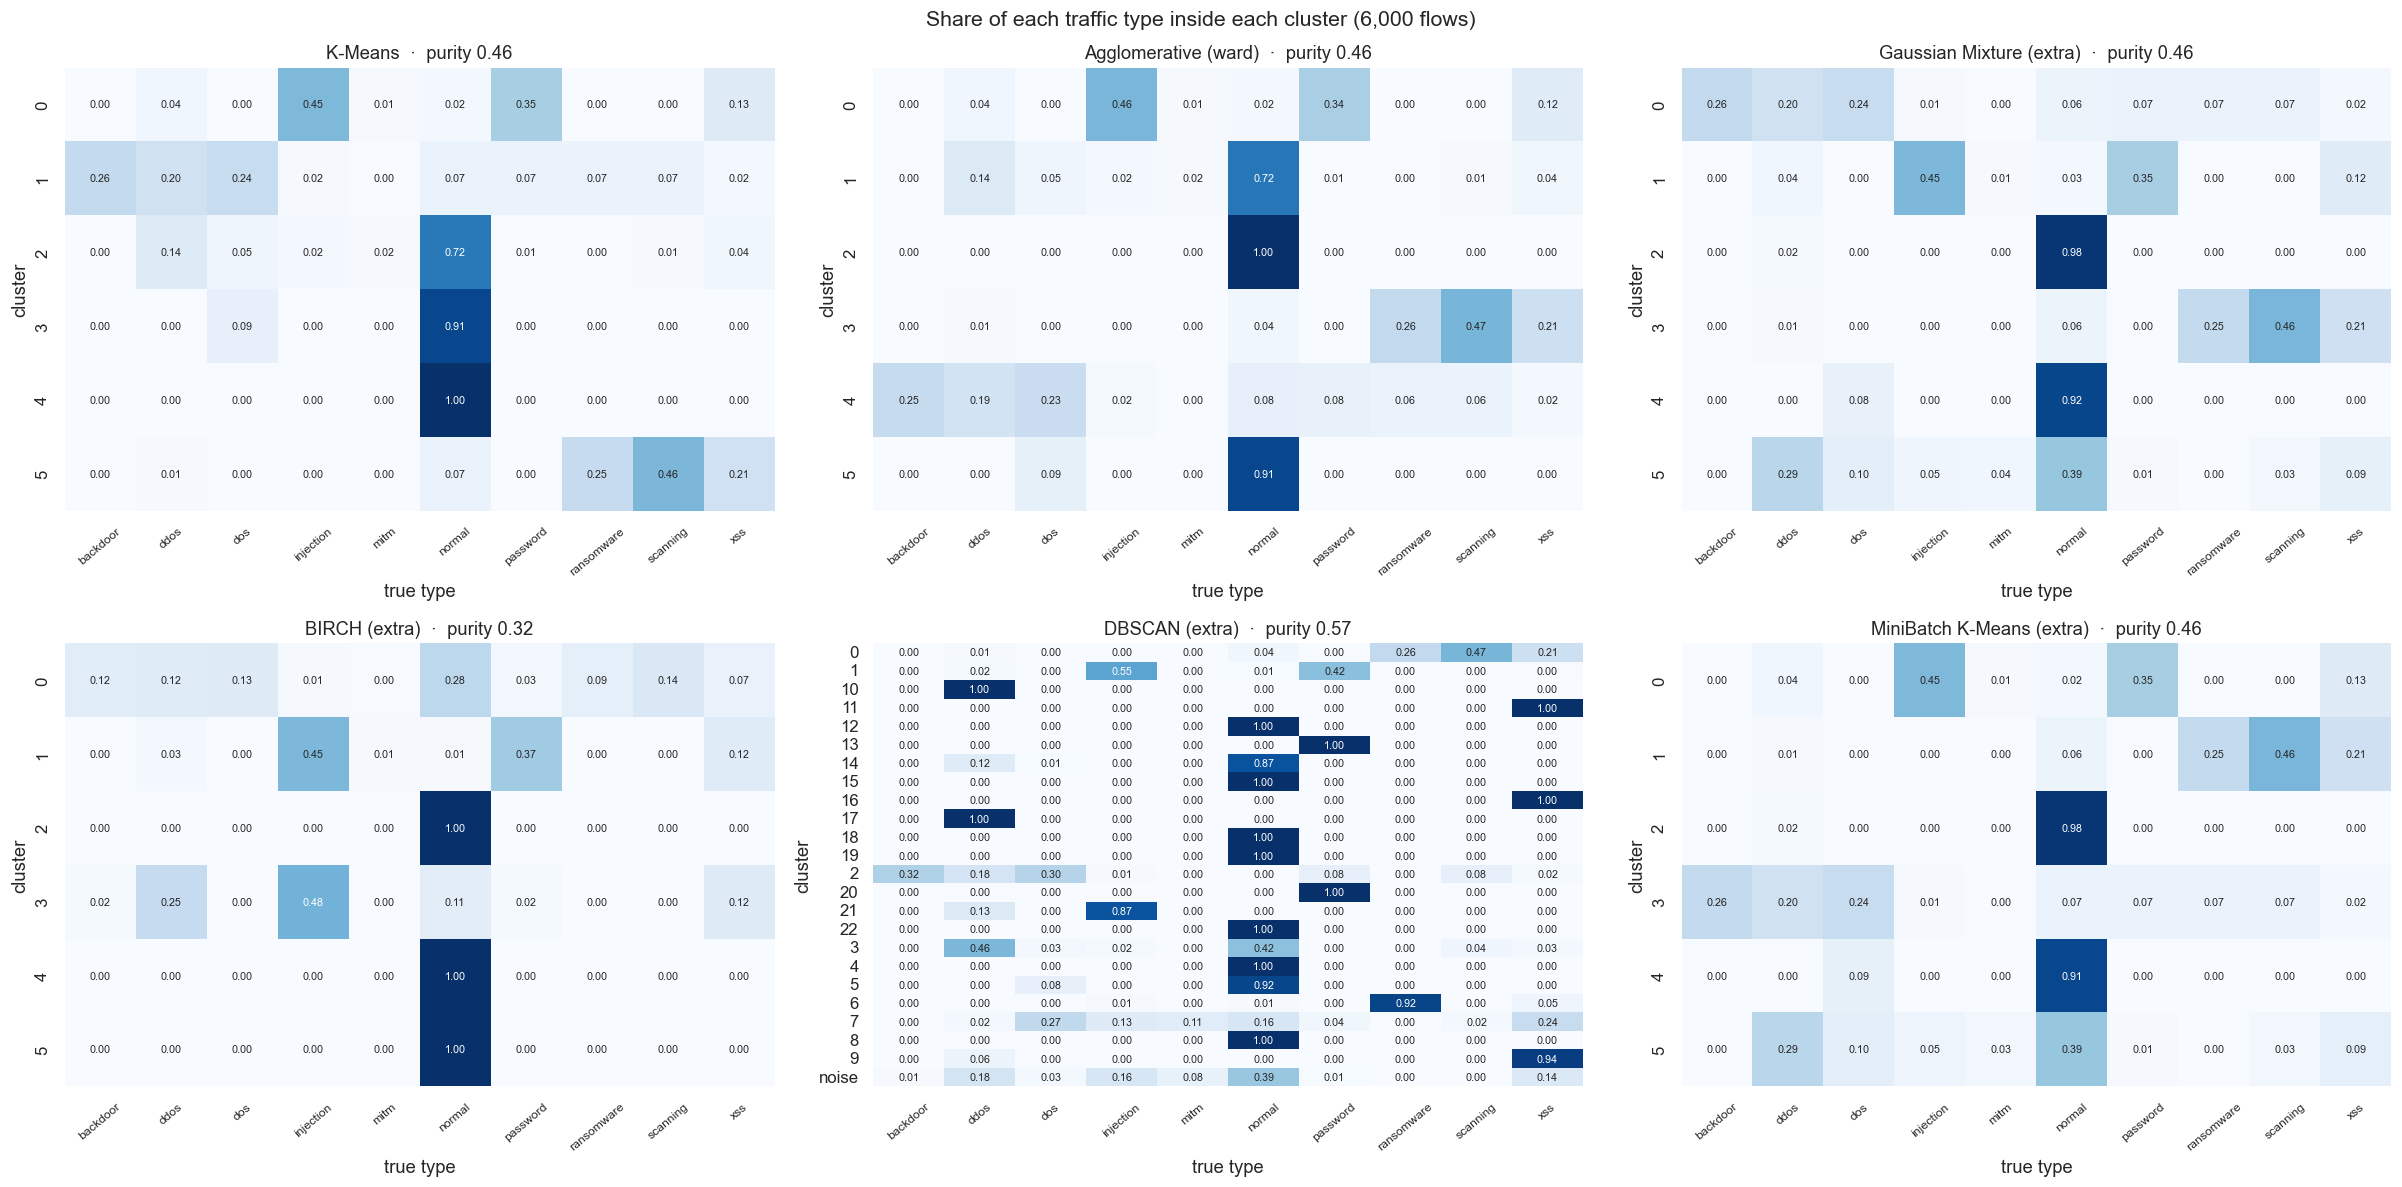

In [35]:
SHOW = ['K-Means', best_agg, 'Gaussian Mixture', 'BIRCH', 'DBSCAN', 'MiniBatch K-Means']
fig, axes = plt.subplots(2, 3, figsize=(22, 11))
for ax, n in zip(axes.ravel(), SHOW):
    lab = CLU_RUN[n]['labels']
    ct = pd.crosstab(pd.Series(np.where(lab < 0, 'noise', lab.astype(str)), name='cluster'), pd.Series(truth_a, name='true type'), normalize='index')
    sns.heatmap(ct, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, cbar=False, ax=ax, annot_kws={'size': 7})
    ax.set_title(f"{n}{'' if CLU_RUN[n]['required'] else ' (extra)'}  ·  purity {clu.loc[n, 'Purity ↑']:.2f}")
    ax.tick_params(axis='x', rotation=40, labelsize=8)
fig.suptitle('Share of each traffic type inside each cluster (6,000 flows)', fontsize=14)
plt.tight_layout(); save(fig, 'clu_02_cluster_vs_type.png'); plt.show()

> **Observation (write in your own words):** Which clusters are almost pure for every algorithm? Which traffic types are always mixed together, and what do they have in common?
>
> _…_

## 2.6 Side by side on the same PCA axes
One PCA (fitted on the 30,000 flows) and the same 6,000 points in every panel, so only the colours change. The last panel shows the true traffic type for reference.

saved results\figures\comparative\clu_03_pca_all.png


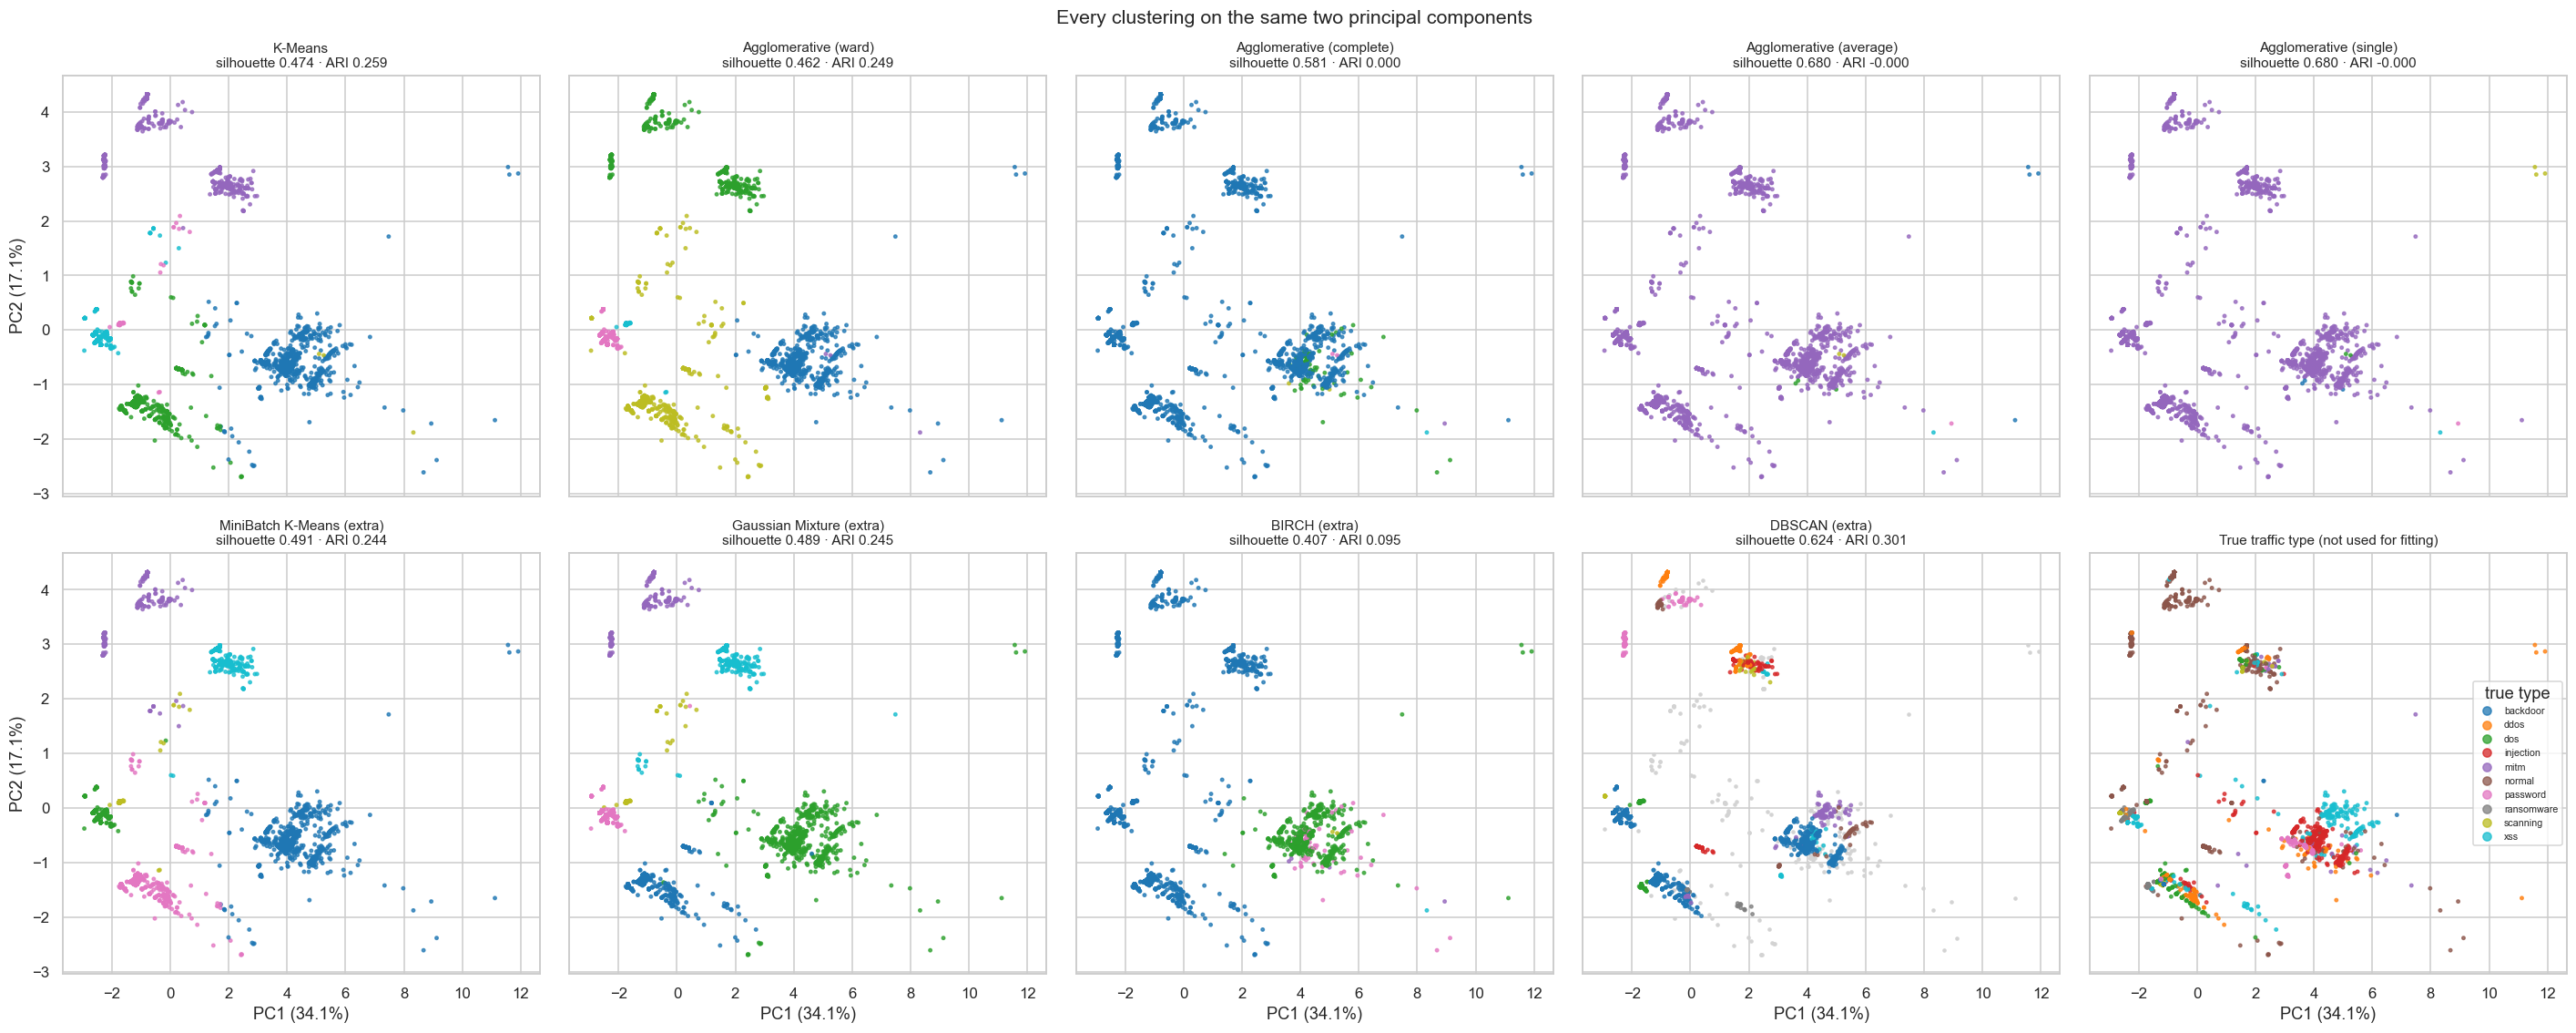

In [36]:
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(X)
P = pca.transform(Xa); ev = pca.explained_variance_ratio_
panels = [(n, CLU_RUN[n]['labels']) for n in ['K-Means'] + [k for k in CLU_RUN if k.startswith('Agglomerative')] +
          ['MiniBatch K-Means', 'Gaussian Mixture', 'BIRCH', 'DBSCAN']]
fig, axes = plt.subplots(2, 5, figsize=(26, 10.5), sharex=True, sharey=True)
for ax, (n, lab) in zip(axes.ravel(), panels):
    ax.scatter(P[lab < 0, 0], P[lab < 0, 1], c='lightgrey', s=4, label='noise')
    sc = ax.scatter(P[lab >= 0, 0], P[lab >= 0, 1], c=lab[lab >= 0], cmap='tab10', s=5, alpha=0.75)
    ax.set_title(f"{n}{'' if CLU_RUN[n]['required'] else ' (extra)'}\nsilhouette {clu.loc[n, 'Silhouette ↑']:.3f} · ARI {clu.loc[n, 'ARI ↑']:.3f}", fontsize=10)
types = pd.Categorical(truth_a)
ax = axes.ravel()[len(panels)]
sc = ax.scatter(P[:, 0], P[:, 1], c=types.codes, cmap='tab10', s=5, alpha=0.75)
ax.legend(sc.legend_elements()[0], list(types.categories), fontsize=7, title='true type', loc='best')
ax.set_title('True traffic type (not used for fitting)', fontsize=10)
for ax in axes[1]: ax.set_xlabel(f'PC1 ({ev[0]:.1%})')
for ax in axes[:, 0]: ax.set_ylabel(f'PC2 ({ev[1]:.1%})')
fig.suptitle('Every clustering on the same two principal components', fontsize=14)
plt.tight_layout(); save(fig, 'clu_03_pca_all.png'); plt.show()

### 2.6.1 t-SNE: K-Means vs Agglomerative vs the true type, on one embedding

saved results\figures\comparative\clu_04_tsne_compare.png


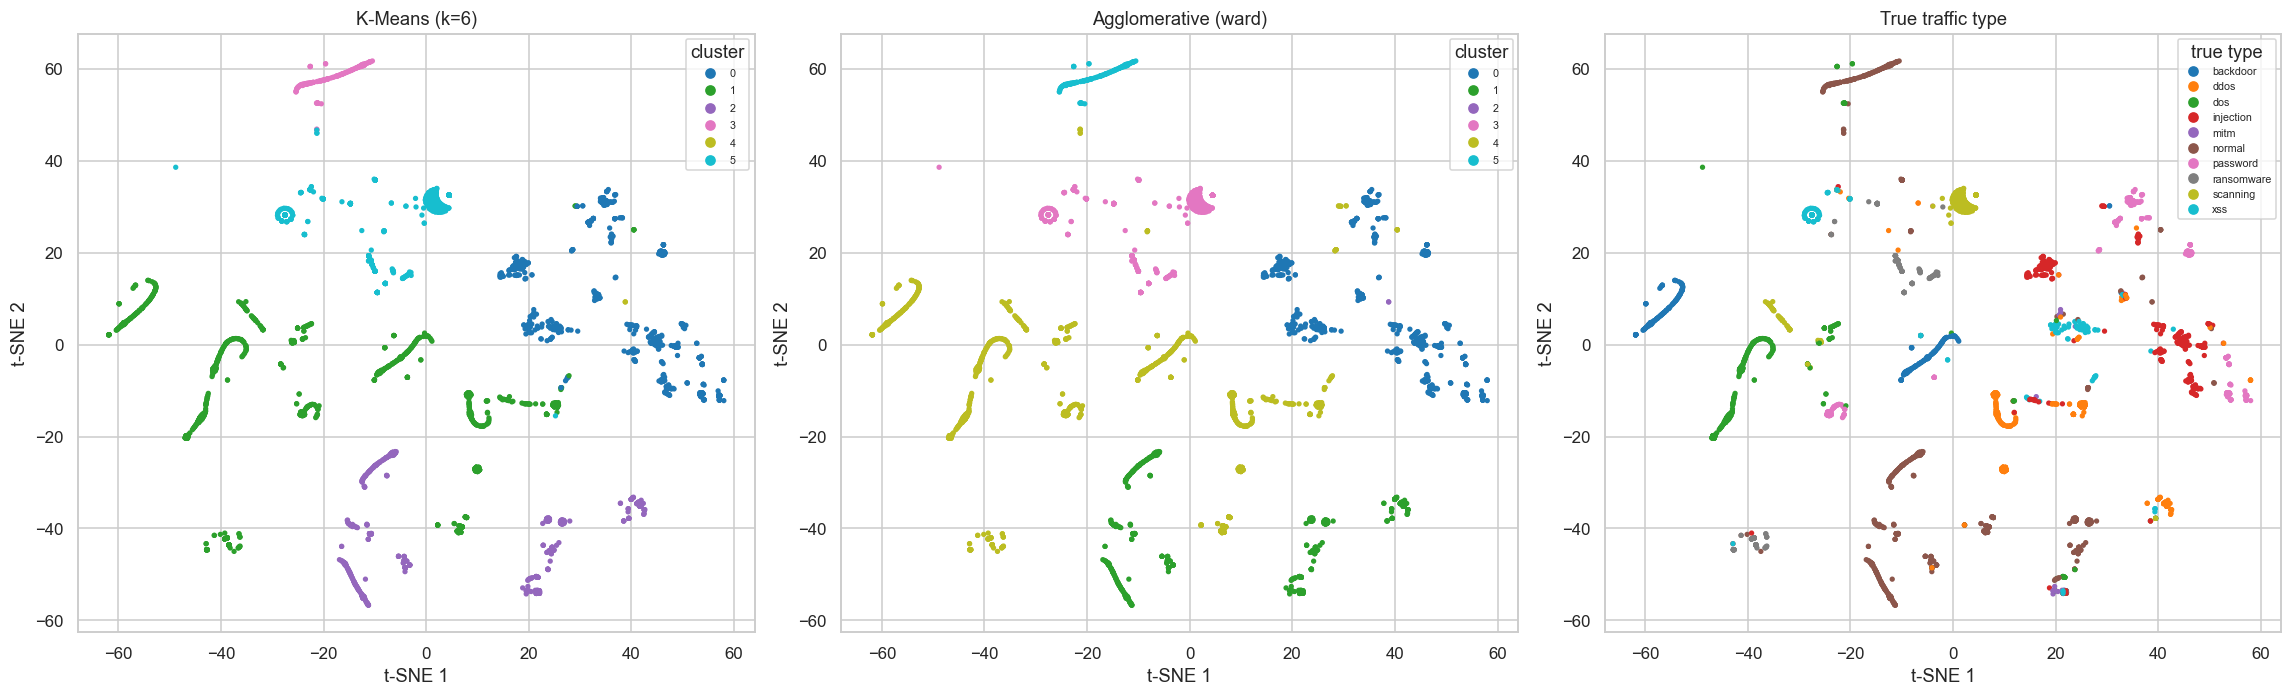

In [37]:
ts_idx = np.arange(N_TSNE)                      # the first 3,000 flows of the 6,000-flow subset
T = TSNE(n_components=2, perplexity=40, init='pca', random_state=RANDOM_STATE).fit_transform(Xa[ts_idx])
fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))
for ax, (title, lab) in zip(axes, [(f'K-Means (k={K_BEST})', CLU_RUN['K-Means']['labels'][ts_idx]),
                                   (best_agg, CLU_RUN[best_agg]['labels'][ts_idx])]):
    sc = ax.scatter(T[:, 0], T[:, 1], c=lab, cmap='tab10', s=6)
    ax.legend(*sc.legend_elements(), title='cluster', fontsize=7); ax.set_title(title)
ty = pd.Categorical(truth_a[ts_idx])
sc = axes[2].scatter(T[:, 0], T[:, 1], c=ty.codes, cmap='tab10', s=6)
axes[2].legend(sc.legend_elements()[0], list(ty.categories), title='true type', fontsize=7); axes[2].set_title('True traffic type')
for ax in axes: ax.set_xlabel('t-SNE 1'); ax.set_ylabel('t-SNE 2')
plt.tight_layout(); save(fig, 'clu_04_tsne_compare.png'); plt.show()

> **Observation (write in your own words):** Where do K-Means and Agglomerative draw different boundaries? Which one follows the true traffic types more closely in the plots?
>
> _…_

## 2.7 Stability: how much do the clusters change between runs?
Five runs. Every run clusters the **same 2,000 probe flows** together with 4,000 other flows drawn at random for that run (and, for the algorithms with a random start, a new seed). Agreement between two runs is the ARI of their labels on the probe flows: 1 means identical clusters.

saved results\figures\comparative\clu_05_stability.png


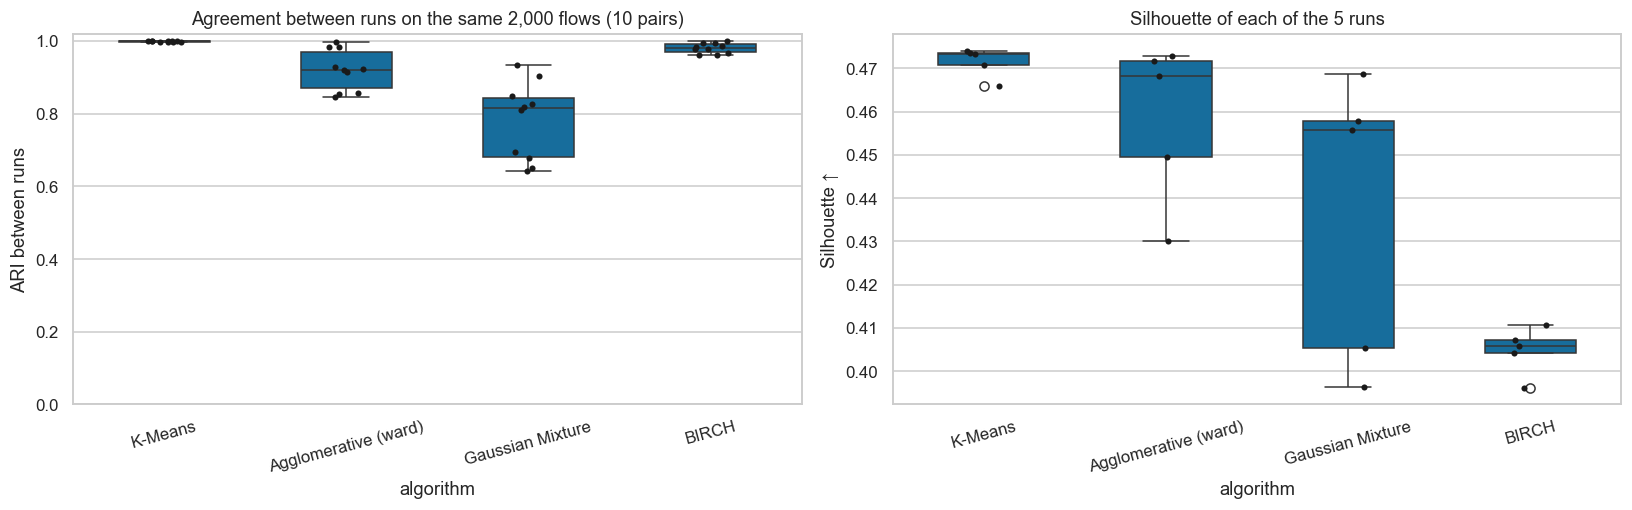

Silhouette ↑         Davies-Bouldin ↓         Calinski-Harabasz ↑           ARI between runs        
                             mean     std             mean     std                mean       std             mean     std
Algorithm                                                                                                                
Agglomerative (ward)       0.4585  0.0185           0.8208  0.0746           2472.2420  150.6340           0.9207  0.0555
BIRCH                      0.4049  0.0054           0.4975  0.0423           1112.4664   39.6139           0.9804  0.0134
Gaussian Mixture           0.4368  0.0333           1.3271  0.2399           1678.1328  178.6490           0.7810  0.1067
K-Means                    0.4716  0.0034           0.7562  0.0042           2532.9415  108.4060           0.9994  0.0008

In [38]:
rest = np.setdiff1d(np.arange(len(X)), agg_idx[:2000])
probe = agg_idx[:2000]
STAB = {'K-Means': lambda Z, s: KMeans(n_clusters=K_BEST, n_init=10, random_state=s).fit_predict(Z),
        'Agglomerative (ward)': lambda Z, s: AgglomerativeClustering(n_clusters=K_BEST, linkage='ward').fit_predict(Z),
        'Gaussian Mixture': lambda Z, s: GaussianMixture(n_components=K_BEST, covariance_type='diag', random_state=s, reg_covar=1e-4).fit(Z).predict(Z),
        'BIRCH': lambda Z, s: Birch(n_clusters=K_BEST, threshold=0.5).fit_predict(Z)}
st_rows, ari_rows = [], []
for n, fn in STAB.items():
    probe_labels = []
    for run in range(5):
        other = np.random.RandomState(100 + run).choice(rest, 4000, replace=False)
        Z = X[np.concatenate([probe, other])]
        lab = fn(Z, run)
        probe_labels.append(lab[:2000])
        st_rows.append({'Algorithm': n, 'run': run + 1, 'Silhouette ↑': silhouette_score(Z, lab),
                        'Davies-Bouldin ↓': davies_bouldin_score(Z, lab), 'Calinski-Harabasz ↑': calinski_harabasz_score(Z, lab)})
    for a, b in combinations(range(5), 2):
        ari_rows.append({'Algorithm': n, 'pair': f'{a + 1}-{b + 1}', 'ARI between runs': adjusted_rand_score(probe_labels[a], probe_labels[b])})
stab = pd.DataFrame(st_rows); pair_ari = pd.DataFrame(ari_rows)
stab.to_csv(os.path.join(OUT, 'clustering_stability_runs.csv'), index=False)
pair_ari.to_csv(os.path.join(OUT, 'clustering_stability_ari.csv'), index=False)
stab_sum = stab.groupby('Algorithm')[['Silhouette ↑', 'Davies-Bouldin ↓', 'Calinski-Harabasz ↑']].agg(['mean', 'std'])
stab_sum[('ARI between runs', 'mean')] = pair_ari.groupby('Algorithm')['ARI between runs'].mean()
stab_sum[('ARI between runs', 'std')] = pair_ari.groupby('Algorithm')['ARI between runs'].std()
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
sns.boxplot(data=pair_ari, x='Algorithm', y='ARI between runs', ax=axes[0], width=0.5)
sns.stripplot(data=pair_ari, x='Algorithm', y='ARI between runs', ax=axes[0], color='k', size=4)
axes[0].set_ylim(0, 1.02); axes[0].set_title('Agreement between runs on the same 2,000 flows (10 pairs)')
sns.boxplot(data=stab, x='Algorithm', y='Silhouette ↑', ax=axes[1], width=0.5)
sns.stripplot(data=stab, x='Algorithm', y='Silhouette ↑', ax=axes[1], color='k', size=4)
axes[1].set_title('Silhouette of each of the 5 runs')
for ax in axes: ax.tick_params(axis='x', rotation=15); ax.set_xlabel('algorithm')
plt.tight_layout(); save(fig, 'clu_05_stability.png'); plt.show()
stab_sum.round(4)

> **Observation (write in your own words):** Which algorithm gives the most repeatable clusters? Agglomerative has no random start; why does it still change between runs?
>
> _…_

## 2.8 Cost: fit time as the data grows
Agglomerative clustering stores all pairwise distances, so its time and memory grow roughly with the square of the number of flows; K-Means grows roughly linearly. Measured here from 1,000 to 10,000 flows.

saved results\figures\comparative\clu_06_runtime.png


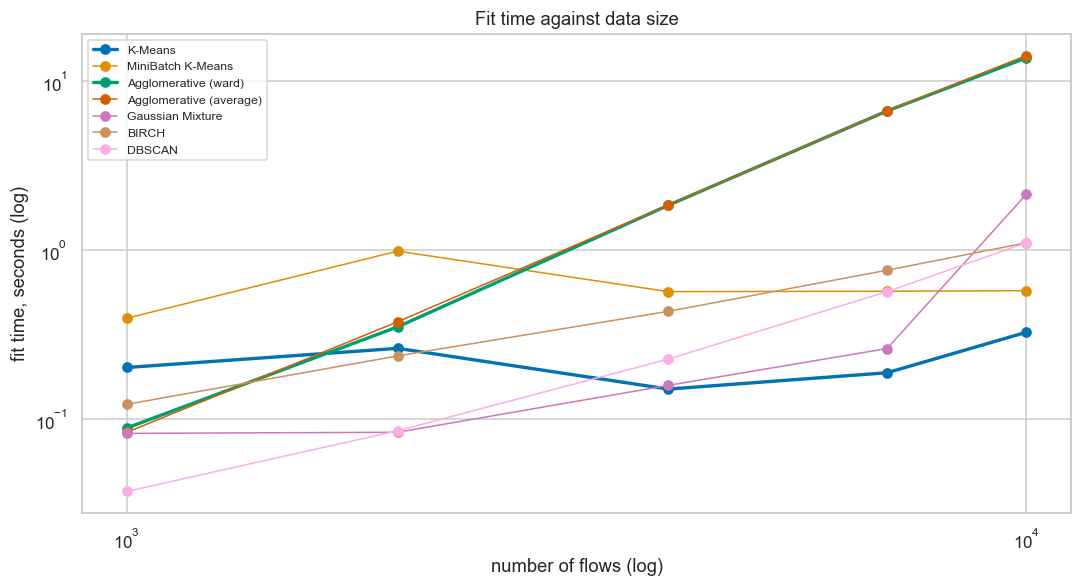

Algorithm,Agglomerative (average),Agglomerative (ward),BIRCH,DBSCAN,Gaussian Mixture,K-Means,MiniBatch K-Means
flows,,,,,,,
1000,0.084,0.089,0.123,0.037,0.083,0.203,0.397
2000,0.378,0.353,0.238,0.086,0.084,0.263,0.991
4000,1.856,1.853,0.436,0.228,0.159,0.151,0.571
7000,6.693,6.689,0.764,0.570,0.263,0.189,0.574
10000,14.231,13.799,1.110,1.111,2.152,0.328,0.578


In [39]:
SIZES = [1000, 2000, 4000, 7000, 10000]
COST = {'K-Means': lambda Z: KMeans(n_clusters=K_BEST, n_init=10, random_state=RANDOM_STATE).fit(Z),
        'MiniBatch K-Means': lambda Z: MiniBatchKMeans(n_clusters=K_BEST, n_init=10, random_state=RANDOM_STATE, batch_size=2048).fit(Z),
        'Agglomerative (ward)': lambda Z: AgglomerativeClustering(n_clusters=K_BEST, linkage='ward').fit(Z),
        'Agglomerative (average)': lambda Z: AgglomerativeClustering(n_clusters=K_BEST, linkage='average').fit(Z),
        'Gaussian Mixture': lambda Z: GaussianMixture(n_components=K_BEST, covariance_type='diag', random_state=RANDOM_STATE, reg_covar=1e-4).fit(Z),
        'BIRCH': lambda Z: Birch(n_clusters=K_BEST, threshold=0.5).fit(Z),
        'DBSCAN': lambda Z: DBSCAN(eps=EPS, min_samples=10).fit(Z)}
cost_rows = []
for nflows in SIZES:
    Z = X[np.random.RandomState(7).choice(len(X), nflows, replace=False)]
    for n, fn in COST.items():
        t0 = time.perf_counter(); fn(Z); cost_rows.append({'Algorithm': n, 'flows': nflows, 'fit time (s)': time.perf_counter() - t0})
cost = pd.DataFrame(cost_rows)
cost.to_csv(os.path.join(OUT, 'clustering_runtime.csv'), index=False)
fig, ax = plt.subplots(figsize=(10, 5.5))
for n in COST:
    d = cost[cost['Algorithm'] == n]
    ax.plot(d['flows'], d['fit time (s)'], 'o-', label=n, lw=2.2 if n in ('K-Means', 'Agglomerative (ward)') else 1)
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel('number of flows (log)'); ax.set_ylabel('fit time, seconds (log)')
ax.set_title('Fit time against data size'); ax.legend(fontsize=8)
plt.tight_layout(); save(fig, 'clu_06_runtime.png'); plt.show()
cost.pivot(index='flows', columns='Algorithm', values='fit time (s)').round(3)

> **Observation (write in your own words):** How would each algorithm cope with all 190,000 flows? Which one would you use at that size?
>
> _…_

## 2.9 Rank heatmap and summary of the clustering comparison

saved results\figures\comparative\clu_07_rank_heatmap.png


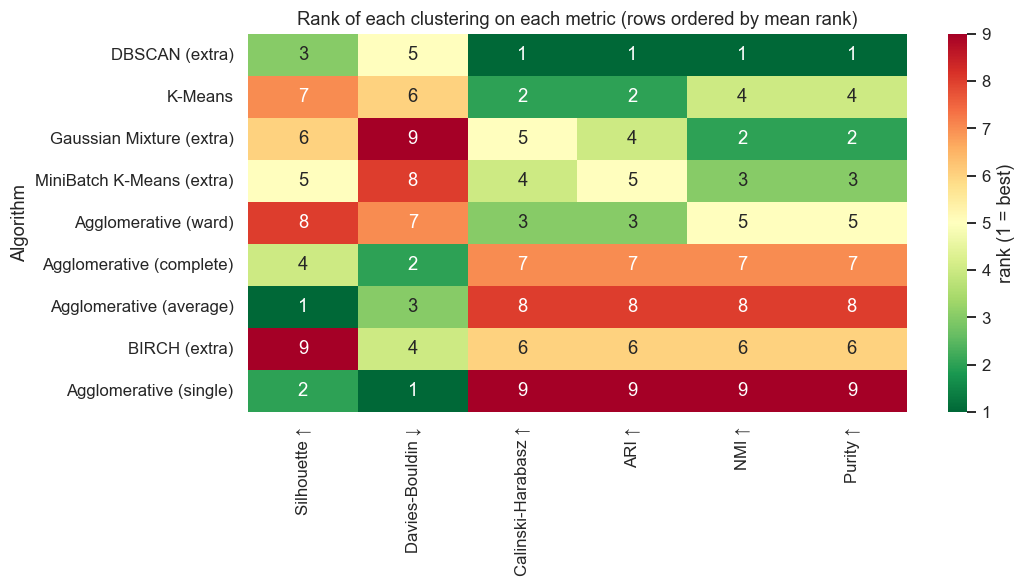

,Silhouette ↑,Davies-Bouldin ↓,Calinski-Harabasz ↑,ARI ↑,NMI ↑,Purity ↑,Mean rank
Algorithm,,,,,,,
DBSCAN,3,5,1,1,1,1,2.00
K-Means,7,6,2,2,4,4,4.17
Gaussian Mixture,6,9,5,4,2,2,4.67
MiniBatch K-Means,5,8,4,5,3,3,4.67
Agglomerative (ward),8,7,3,3,5,5,5.17
Agglomerative (complete),4,2,7,7,7,7,5.67
Agglomerative (average),1,3,8,8,8,8,6.00
BIRCH,9,4,6,6,6,6,6.17
Agglomerative (single),2,1,9,9,9,9,6.50


In [40]:
rank_cols = ['Silhouette ↑', 'Davies-Bouldin ↓', 'Calinski-Harabasz ↑', 'ARI ↑', 'NMI ↑', 'Purity ↑']
cr = pd.DataFrame({c: clu[c].rank(ascending='↓' in c, method='min') for c in rank_cols}).astype(int)
cr['Mean rank'] = cr.mean(axis=1)
cr = cr.sort_values('Mean rank')
cr.to_csv(os.path.join(OUT, 'clustering_ranks.csv'))
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.heatmap(cr[rank_cols], annot=True, fmt='d', cmap='RdYlGn_r', cbar_kws={'label': 'rank (1 = best)'}, ax=ax)
ax.set_yticklabels([f"{n}{'' if CLU_RUN[n]['required'] else ' (extra)'}" for n in cr.index], rotation=0)
ax.set_title('Rank of each clustering on each metric (rows ordered by mean rank)')
plt.tight_layout(); save(fig, 'clu_07_rank_heatmap.png'); plt.show()
cr.round(2)

> **Observation (write in your own words):** Taking the scores, the cluster contents, the stability and the cost together: which of the two required algorithms would you use for this traffic, and why?
>
> _…_